# Terraria: redes de fabricação e obtenção

Este trabalho usa dados do [Terraria Progress Tracker](https://github.com/Doeschi/Terraria-Progress-Tracker/tree/e1726af0908d928a3e2fa437286558827a6dd3b0/pipeline/data_readable), versão 1.4.5, para responder ao [enunciado](../docs/LEIA.md).

Duas representações, com papéis diferentes e sem mistura entre elas:

- **`G`** — grafo semântico dirigido com itens, receitas, estações, bosses, biomas, NPCs, drops, eventos, marcos e condições. Serve para explicar **de onde vem** cada item e para desenhar as cadeias de dependência. Nenhuma medida estrutural do trabalho sai de `G`.
- **`H`** — projeção simples e não dirigida **apenas** das relações ingrediente→produto. É a rede analisada: distribuições, centralidades, comparação com redes sintéticas, robustez, difusão, preservação e navegação.

Roteiro: **1** dados · **2** construção de `G` · **3** progressão e limites · **4** exemplos de dependências · **5** projeção `H` · **6** distribuições de métricas · **7** os três vértices mais importantes · **8** comparação com redes sintéticas · **9** classificação da rede · **10** robustez, difusão, preservação e navegação · **11** conclusões.

A conectividade representa relações possíveis entre receitas, não uma simulação de jogo.

## 1. Dados e arquivos

In [1]:
import json
import random
from pathlib import Path
from collections import Counter

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/raw/items.json").exists())
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
names = ["items", "recipes", "bosses", "biomes", "milestones", "drops", "conditions", "bestiary", "events", "vendors", "shops"]
data = {}
for name in names:
    data[name] = json.loads((root / "data/raw" / f"{name}.json").read_text(encoding="utf-8"))
items = {item["key"]: item for item in data["items"]}
recipes = data["recipes"]["recipes"]
bosses = {boss["id"]: boss for boss in data["bosses"]["bosses"]}
biomes = {biome["id"]: biome for biome in data["biomes"]}
milestones = {mark["id"]: mark for mark in data["milestones"]}
vendors = {vendor["id"]: vendor for vendor in data["vendors"]}

In [3]:
display(pd.DataFrame([{"arquivo": name, "entradas ou seções": len(data[name]),
                       "campos": ", ".join(list(data[name][0] if isinstance(data[name], list) else data[name])[:8])}
                      for name in names]))

,arquivo,entradas ou seções,campos
0,items,6186,"key, id, name, internalName, page, url, icon, ..."
1,recipes,4,"stations, groups, recipes, shimmer"
2,bosses,3,"stages, bosses, ignoreItems"
3,biomes,18,"id, name, icon, count"
4,milestones,16,"id, name, icon, count"
5,drops,4,"sources, items, groups, areas"
6,conditions,2,"groups, conditions"
7,bestiary,2,"types, entries"
8,events,18,"id, name, icon, count"
9,vendors,24,"id, name, icon, count, head"


## 2. Construção de G

Identificadores têm prefixos. Receitas distintas são alternativas; seus **slots são simultâneos** e as opções dentro de cada slot são alternativas. Estações listadas na receita são requisitos conjuntos, e itens que fornecem uma mesma estação são alternativas. Nós de rota separam ofertas e linhas de drop, inclusive suas condições. Os tokens são mantidos com o texto original: sua lista isolada não estabelece se são alternativas ou requisitos conjuntos. Arestas paralelas preservam o número do slot e outras ocorrências. Consulte os atributos de cada rota para probabilidades e texto original. Não confunda um caminho individual com uma receita completa.

In [4]:
groups = data["recipes"]["groups"]
stations = data["recipes"]["stations"]
ETAPAS = {"pre-hardmode": "pré-Hardmode", "hardmode": "Hardmode", "event": "evento"}

def desktop(record):
    return "desktop" in record.get("platforms", ["desktop"])

def options(slot):
    if "item" in slot:
        return [slot["item"]]
    return groups[slot["group"]]["items"]

G = nx.MultiDiGraph()
def entity(node, name, kind, **attributes):
    G.add_node(node, name=name, type=kind, **attributes)

def relation(origin, destination, name, **attributes):
    if origin not in G or destination not in G:
        raise ValueError(f"Referência ausente: {origin} → {destination} ({name})")
    G.add_edge(origin, destination, relation=name, **attributes)

for key, item in items.items():
    if desktop(item):
        entity(f"item:{key}", item["name"], "item")
# Os 32 bosses compartilham um tipo e uma cor; a etapa de bosses.json fica no rótulo e no atributo.
for boss in bosses.values():
    entity(f"boss:{boss['id']}", f"{boss['name']}\nboss · {ETAPAS[boss['stage']]}", "boss",
           etapa=boss["stage"])
for kind, records in [("biome", biomes.values()), ("milestone", milestones.values()),
                      ("event", data["events"]), ("npc", data["vendors"]),
                      ("condition", data["conditions"]["conditions"])]:
    for record in records:
        entity(f"{kind}:{record['id']}", record["name"], kind)


In [5]:
for name, station in stations.items():
    kind = "condition" if station.get("condition") else "station"
    entity(f"{kind}:{name}", name, kind)
    for item_key in station.get("items", []):
        assert item_key in items
        if f"item:{item_key}" in G:
            relation(f"item:{item_key}", f"{kind}:{name}", "fornece estação", escolha="alternativa")

for index, recipe in enumerate(recipes):
    assert recipe["result"] in items and recipe["stations"] is not None
    for slot in recipe["ingredients"]:
        assert options(slot) and all(key in items for key in options(slot))

def viavel(recipe):
    return (desktop(recipe) and f"item:{recipe['result']}" in G
            and all(any(f"item:{key}" in G for key in options(slot)) for slot in recipe["ingredients"]))

# O índice da lista não identifica nada: o rótulo traz produto, quantidade e estação.
aceitas = [index for index, recipe in enumerate(recipes) if viavel(recipe)]
alternativas = Counter(recipes[index]["result"] for index in aceitas)

def rotulo_receita(recipe, posicao):
    produto = items[recipe["result"]]["name"]
    quantidade = f" ×{recipe['amount']}" if recipe["amount"] > 1 else ""
    # Estações na mesma receita são exigidas juntas, como Loom + Ecto Mist.
    estacao = " + ".join(recipe["stations"])
    total = alternativas[recipe["result"]]
    variante = f" · alt. {posicao}/{total}" if total > 1 else ""
    return f"{produto}{quantidade}\n⚒ {estacao}{variante}"

ordinal = Counter()
for index in aceitas:
    recipe = recipes[index]
    ordinal[recipe["result"]] += 1
    node = f"recipe:{index}"
    entity(node, rotulo_receita(recipe, ordinal[recipe["result"]]), "recipe",
           produto=recipe["result"], indice=index, dados=recipe)
    relation(node, f"item:{recipe['result']}", "produz", quantidade=recipe["amount"])
    for slot_number, slot in enumerate(recipe["ingredients"]):
        for key in options(slot):
            if f"item:{key}" in G:
                relation(f"item:{key}", node, "ingrediente", slot=slot_number,
                         quantidade=slot["amount"], grupo=slot.get("group"))
    for name in recipe["stations"]:
        assert name in stations
        kind = "condition" if stations[name].get("condition") else "station"
        relation(f"{kind}:{name}", node, "requisito de fabricação")


In [6]:
def rotulo_rota(prefixo, detalhe):
    return f"{prefixo}\n{detalhe}" if detalhe else prefixo

def taxa_curta(row):
    # O campo `rate` chega a 83 caracteres; o texto completo permanece em `dados`.
    taxa = (row.get("rate") or "").split(" · ")[0].strip()
    return taxa if len(taxa) <= 20 else taxa[:19] + "…"

sources = data["drops"]["sources"]
TIPO_FONTE = {"npc": "enemy", "bag": "bag", "container": "container"}

def tipo_da_fonte(source_id):
    """Boss tem nó próprio; sacola e contêiner ficam em tipos distintos para não esconder baús."""
    source = sources[source_id]
    if source_id in bosses and source["kind"] == "npc":
        return "boss"
    return TIPO_FONTE[source["kind"]]

# Uma fonte sem identificação segura no bestiário permanece uma fonte própria.
for source_id, source in sources.items():
    if not desktop(source):
        continue
    kind = tipo_da_fonte(source_id)
    node = f"{kind}:{source_id}"
    if kind != "boss":
        entity(node, source["name"], kind, origem=source["kind"])
    for field, contexto in [("biomes", "biome"), ("events", "event")]:
        for value in source.get(field, []):
            relation(f"{contexto}:{value}", node, "encontro associado")

for boss_id, boss in bosses.items():
    for source_id in boss["sources"]:
        assert source_id in sources
        if desktop(sources[source_id]) and source_id != boss_id:
            relation(f"boss:{boss_id}", f"{tipo_da_fonte(source_id)}:{source_id}",
                     "agrupa fonte", origem="bosses.json")

for item_key, rows in data["drops"]["items"].items():
    assert item_key in items
    for index, row in enumerate(rows):
        assert row["source"] in sources
        source = sources[row["source"]]
        if f"item:{item_key}" not in G or not desktop(source):
            continue
        route = f"drop:{item_key}:{index}"
        entity(route, rotulo_rota("Drop", taxa_curta(row)), "drop",
               item=item_key, fonte=row["source"], dados=row)
        relation(f"{tipo_da_fonte(row['source'])}:{row['source']}", route, "fonte do drop")
        relation(route, f"item:{item_key}", "obtém item")
        for condition in row.get("conditions", []):
            relation(f"condition:{condition}", route, "condição da rota")
        for biome in row.get("biomes", []):
            relation(f"biome:{biome}", route, "contexto da rota")


In [7]:
for item_key, rows in data["shops"].items():
    assert item_key in items
    if f"item:{item_key}" not in G:
        continue
    for index, row in enumerate(rows):
        route = f"sale:{item_key}:{index}"
        entity(route, rotulo_rota("Oferta", vendors[row["vendor"]]["name"]), "sale",
               item=item_key, fonte=row["vendor"], dados=row)
        relation(f"npc:{row['vendor']}", route, "oferece")
        relation(route, f"item:{item_key}", "vende")
        for condition in row.get("conditions", []):
            relation(f"condition:{condition}", route, "condição da rota")
        for biome in row.get("biomes", []):
            relation(f"biome:{biome}", route, "contexto da rota")

# Shimmer é outra rota, sem misturá-la às receitas.
for index, row in enumerate(data["recipes"]["shimmer"]):
    assert row["result"] in items
    for key in options(row):
        assert key in items
        if f"item:{key}" in G and f"item:{row['result']}" in G:
            relation(f"item:{key}", f"item:{row['result']}", "conversão Shimmer",
                     quantidade=row["amount"], grupo=row.get("group"), dados=row)

for key, item in items.items():
    if f"item:{key}" not in G:
        continue
    if item.get("milestone"):
        relation(f"milestone:{item['milestone']}", f"item:{key}", "disponibilidade estimada",
                 explicacao=item.get("milestoneVia"), origem="items.json")

# As entradas do bestiário mantêm identidade independente das fontes sem junção inequívoca.
for entry in data["bestiary"]["entries"]:
    if not desktop(entry):
        continue
    node = f"bestiary:{entry['id']}"
    entity(node, entry["name"], "bestiary")
    for biome in entry.get("biomes", []):
        relation(f"biome:{biome}", node, "encontro associado")
    for event in entry.get("events", []):
        relation(f"event:{event}", node, "encontro associado")
    # Apenas identificações simultaneamente iguais por nome e npcId são associadas.
    for source_id, source in sources.items():
        if (desktop(source) and source["kind"] == "npc" and source.get("npcId") is not None
                and source.get("npcId") == entry.get("npcId") and source["name"] == entry["name"]):
            relation(node, f"{tipo_da_fonte(source_id)}:{source_id}", "mesma fonte documentada")


## 3. Progressão, aquisição e limites

Os marcos do tracker são estimativas de disponibilidade, **não pré-requisitos universais**. Na pequena tabela abaixo, `qualquer` é OR e `todos` é AND; conquistas opcionais não são ordenadas numa cadeia única. As regras suplementares usam a [wiki oficial: Hardmode](https://terraria.wiki.gg/wiki/Hardmode), [progressão](https://terraria.wiki.gg/wiki/Guide:Game_progression) e [Plantera](https://terraria.wiki.gg/wiki/Plantera). Elas pressupõem progressão normal de um mesmo mundo, não todas as possibilidades entre mundos e seeds. A fonte local associa Mothron a Plantera e a [página da wiki](https://terraria.wiki.gg/wiki/Mothron) registra a nota de versão 1.4.1 do desktop: Mothron só aparece depois de Plantera derrotada. Mantemos a relação como regra desta versão dos dados, ainda assim restrita à progressão normal. Ela entra em `G` como a aresta `boss:plantera → enemy:mothron`, e é por isso que Plantera aparece junto do Mothron no diagrama em vez de flutuar ao lado da Terra Blade.

Os dados não estruturam geração geológica nem a ferramenta de mineração: `milestoneVia` é texto. Para Chlorophyte, mostramos esse texto, sem inventar aresta de mineração ou bioma. Condições de loja pertencem à oferta, não a todos os métodos de aquisição.

In [8]:
progress = {
    "wall-of-flesh": ("todos", ["wall-of-flesh"]),
    "any-mech": ("qualquer", ["the-twins", "the-destroyer", "skeletron-prime"]),
    "all-mechs": ("todos", ["the-twins", "the-destroyer", "skeletron-prime"]),
    "evil-boss": ("qualquer", ["eater-of-worlds", "brain-of-cthulhu"]),
}
for mark in milestones:
    if mark in bosses and mark not in progress:
        progress[mark] = ("todos", [mark])
for mark, (logic, boss_ids) in progress.items():
    G.nodes[f"milestone:{mark}"]["logica_bosses"] = logic
    for boss_id in boss_ids:
        relation(f"boss:{boss_id}", f"milestone:{mark}", "contribui para marco", logica=logic)
relation("milestone:wall-of-flesh", "condition:hardmode", "desbloqueia", fonte="https://terraria.wiki.gg/wiki/Hardmode")
entity("requirement:plantera", "Invocação de Plantera", "requirement")
G.nodes["requirement:plantera"]["logica"] = "todos"
relation("milestone:all-mechs", "requirement:plantera", "requisito", fonte="https://terraria.wiki.gg/wiki/Plantera")
relation("condition:hardmode", "requirement:plantera", "requisito", fonte="https://terraria.wiki.gg/wiki/Hardmode")
relation("requirement:plantera", "boss:plantera", "habilita invocação")
relation("boss:plantera", "enemy:mothron", "habilita aparição",
         fonte="https://terraria.wiki.gg/wiki/Mothron")
relation("milestone:plantera", "boss:golem", "acesso usual ao templo", fonte="https://terraria.wiki.gg/wiki/Guide:Game_progression")
print("Marcos com regras AND/OR:")
display(pd.DataFrame([{"marco": mark, "lógica": logic, "bosses": ", ".join(ids)} for mark, (logic, ids) in progress.items()]))

Marcos com regras AND/OR:


,marco,lógica,bosses
0,wall-of-flesh,todos,wall-of-flesh
1,any-mech,qualquer,"the-twins, the-destroyer, skeletron-prime"
2,all-mechs,todos,"the-twins, the-destroyer, skeletron-prime"
3,evil-boss,qualquer,"eater-of-worlds, brain-of-cthulhu"
4,king-slime,todos,king-slime
5,eye-of-cthulhu,todos,eye-of-cthulhu
6,queen-bee,todos,queen-bee
7,deerclops,todos,deerclops
8,skeletron,todos,skeletron
9,queen-slime,todos,queen-slime


In [9]:
assert len({i["key"] for i in data["items"]}) == len(data["items"])
assert all(info.get("name") and info.get("type") for _, info in G.nodes(data=True))
assert all(edge.get("relation") for *_, edge in G.edges(data=True))
for index, recipe in enumerate(recipes):
    node = f"recipe:{index}"
    if node not in G:
        continue
    for slot_number, slot in enumerate(recipe["ingredients"]):
        expected = {f"item:{key}" for key in options(slot) if f"item:{key}" in G}
        actual = {u for u, _, edge in G.in_edges(node, data=True)
                  if edge["relation"] == "ingrediente" and edge["slot"] == slot_number}
        assert actual == expected
assert G.nodes["milestone:any-mech"]["logica_bosses"] == "qualquer"
assert G.nodes["milestone:all-mechs"]["logica_bosses"] == "todos"
assert G.nodes["milestone:evil-boss"]["logica_bosses"] == "qualquer"
assert G.nodes["requirement:plantera"]["logica"] == "todos"
assert set(G.predecessors("requirement:plantera")) == {"milestone:all-mechs", "condition:hardmode"}
terra_recipe = next(f"recipe:{i}" for i, r in enumerate(recipes) if r["result"] == "TerraBlade" and f"recipe:{i}" in G)
terra_slots = {edge["slot"]: u for u, _, edge in G.in_edges(terra_recipe, data=True) if edge["relation"] == "ingrediente"}
assert set(terra_slots.values()) == {"item:BrokenHeroSword", "item:TrueExcalibur", "item:TrueNightsEdge"}
assert G.has_edge("enemy:mothron", "drop:BrokenHeroSword:0")
assert G.has_edge("boss:plantera", "enemy:mothron") and G.nodes["boss:plantera"]["etapa"] == "hardmode"
assert G.nodes["bag:treasure-bag-plantera"]["type"] == "bag"
assert G.nodes["container:gold-chest-dungeon"]["type"] == "container"
assert G.has_edge("event:solar-eclipse", "enemy:mothron")
assert G.has_edge("biome:jungle", "enemy:giant-tortoise")
leaf = G.nodes["sale:LeafWings:0"]["dados"]
assert {"hardmode", "night", "after-plantera"} <= set(leaf["conditions"]) and "jungle" in leaf["biomes"]
display(pd.DataFrame(Counter(info["type"] for _, info in G.nodes(data=True)).items(), columns=["tipo", "vértices"]))
print(f"G: {G.number_of_nodes():,} vértices e {G.number_of_edges():,} relações")

,tipo,vértices
0,item,6184
1,boss,32
2,biome,18
3,milestone,16
4,event,18
5,npc,24
6,condition,75
7,station,35
8,recipe,3655
9,enemy,368


G: 15,553 vértices e 32,362 relações


### 3.1 Como o jogo progride, segundo as wikis

A progressão do Terraria é uma escada de bosses que libera materiais e estações; não é uma ordem única de itens. O resumo abaixo vem das páginas listadas no [README](../README.md) e serve para ler as figuras e os marcos de `items.json`.

| Etapa | Portão | O que passa a existir |
|---|---|---|
| Pré-Hardmode inicial | — | Copper, Iron, Silver e Gold; Work Bench, Furnace e Iron/Lead Anvil |
| Pré-Hardmode médio | Eye of Cthulhu, Eater of Worlds **ou** Brain of Cthulhu, Skeletron | Demonite/Crimtane, Meteorite, Hellstone e Hellforge; Demon/Crimson Altar |
| Hardmode | **Wall of Flesh** | Cobalt/Palladium → Mythril/Orichalcum → Adamantite/Titanium, cada minério exigindo a picareta do nível anterior; Mythril/Orichalcum Anvil e Adamantite/Titanium Forge |
| Pós-mecânicos | The Twins, The Destroyer e Skeletron Prime | Hallowed Bar e Souls of Sight, Might e Fright; Drax ou Pickaxe Axe, únicas ferramentas capazes de minerar Chlorophyte |
| Pós-Plantera | **Plantera** | Jungle Temple e Golem; Mothron passa a aparecer no Solar Eclipse |
| Fim de jogo | Lunatic Cultist e eventos lunares | Luminite, Ancient Manipulator e Moon Lord |

A cadeia da Terra Blade atravessa essa escada inteira, e é por isso que ela serve de exemplo: Hellstone e Demonite/Crimtane são pré-Hardmode, a Hallowed Bar exige os três mecânicos, o Chlorophyte exige a picareta que esses mesmos bosses liberam e a Broken Hero Sword exige Plantera.

A pesquisa também confirma duas decisões do modelo. As opções dentro de um slot correspondem aos grupos de ingredientes alternativos documentados pelo jogo, como `Any Wood` e `Any Iron Bar`, e por isso são alternativas reais e não suposição nossa. O Shimmer não é receita e sim transmutação por imersão, e por isso continua em arestas próprias, fora de `recipe:`.

Para consultar qualquer vértice sem abrir os JSONs, as duas funções abaixo imprimem o conteúdo: `descrever` mostra as relações de entrada e saída de um vértice e `receitas_de` lista todas as receitas que produzem um item. O exemplo usa `recipe:3234`, que antes aparecia na figura apenas como `Receita 3234`.


In [10]:
def legivel(node):
    return G.nodes[node]["name"].replace("\n", " ")

def descrever(node):
    """Cartão de um vértice: responde 'que receita ou rota é essa?' sem abrir os JSONs."""
    info = G.nodes[node]
    linhas = [{"direção": "entra", "relação": edge["relation"], "vértice": u, "nome": legivel(u),
               "quantidade": edge.get("quantidade"), "slot": edge.get("slot")}
              for u, _, edge in G.in_edges(node, data=True)]
    linhas += [{"direção": "sai", "relação": edge["relation"], "vértice": v, "nome": legivel(v),
                "quantidade": edge.get("quantidade"), "slot": edge.get("slot")}
               for _, v, edge in G.out_edges(node, data=True)]
    display(Markdown(f"**{node}** — {legivel(node)} (tipo: `{info['type']}`)"))
    display(pd.DataFrame(linhas).sort_values(["direção", "relação", "slot"], na_position="last"))
    if info.get("dados"):
        print("dados originais:", json.dumps(info["dados"], ensure_ascii=False))

def receitas_de(item_key):
    """Todas as receitas de G que produzem o item, com ingredientes por slot."""
    linhas = []
    for node in G.predecessors(f"item:{item_key}"):
        if G.nodes[node]["type"] != "recipe":
            continue
        recipe = G.nodes[node]["dados"]
        linhas.append({"vértice": node, "produz": f"{items[recipe['result']]['name']} ×{recipe['amount']}",
                       "estação": " + ".join(recipe["stations"]),
                       "ingredientes": " + ".join(f"{slot['amount']}× " + " ou ".join(items[k]["name"] for k in options(slot))
                                                  for slot in recipe["ingredients"])})
    return pd.DataFrame(linhas).sort_values("vértice")

descrever("recipe:3234")
display(receitas_de("TerraBlade"))


**recipe:3234** — Onyx Blaster ⚒ Mythril Anvil (tipo: `recipe`)

,direção,relação,vértice,nome,quantidade,slot
0,entra,ingrediente,item:DarkShard,Dark Shard,2.0,0.0
1,entra,ingrediente,item:Shotgun,Shotgun,1.0,1.0
2,entra,ingrediente,item:SoulofNight,Soul of Night,10.0,2.0
3,entra,requisito de fabricação,station:Mythril Anvil,Mythril Anvil,NaN,NaN
4,sai,produz,item:OnyxBlaster,Onyx Blaster,1.0,NaN


dados originais: {"result": "OnyxBlaster", "amount": 1, "stations": ["Mythril Anvil"], "ingredients": [{"item": "DarkShard", "amount": 2}, {"item": "Shotgun", "amount": 1}, {"item": "SoulofNight", "amount": 10}]}


,vértice,produz,estação,ingredientes
0,recipe:3177,Terra Blade ×1,Mythril Anvil,1× Broken Hero Sword + 1× True Excalibur + 1× ...


## 4. Exemplos de dependências

A figura padrão é **focada**: mostra a cadeia principal de fabricação até `profundidade` níveis acima do item-alvo e, para cada ingrediente que não é fabricado nesse recorte, a fonte direta que o entrega — boss, inimigo, contêiner ou vendedor. O marco entra apenas quando é a única explicação do item, caso do Chlorophyte Ore. O modo **detalhado** (`detalhado=True`) desenha a cadeia inteira e mantém o vértice de rota, que carrega a taxa do drop ou o nome do vendedor.

O desenho é em camadas: o alvo fica no topo e cada nível abaixo está a um passo dirigido de distância, então minérios, fontes e bosses ficam na base. Nada é removido de `G`: o recorte vale só para a figura, e a contagem impressa informa quantas rotas alternativas ficaram de fora.

Cores e formas são fixas em todas as figuras:

| Tipo | Cor | Forma |
|---|---|---|
| item | azul-claro | círculo |
| receita | âmbar, com produto, quantidade e estação | retângulo |
| **boss** | **vermelho, igual para os 32, com a etapa no rótulo** | **hexágono** |
| inimigo | salmão | círculo |
| contêiner e sacola | cinza | retângulo |
| bioma | verde | retângulo |
| evento | azul-escuro | retângulo |
| NPC vendedor | magenta | retângulo |
| marco que destrava | roxo | losango |
| rota de drop ou de compra | cinza-claro, com a taxa ou o vendedor | retângulo |

As arestas distinguem o papel da relação: laranja para `produz`, cinza para `ingrediente`, azul-escuro para obtenção, vermelho tracejado para o boss que destrava uma fonte e roxo tracejado para marco. Uma seta de uma opção não dispensa os outros slots.

In [11]:
# Paleta fixa: cada tipo tem uma cor e uma forma, e os 32 bosses usam sempre o mesmo vermelho.
CORES = {"item": "#8ecae6", "recipe": "#ffb703", "boss": "#c1121f", "enemy": "#f4845f",
         "container": "#adb5bd", "bag": "#ced4da", "biome": "#52b788", "event": "#3d5a80",
         "npc": "#f72585", "milestone": "#9d4edd", "condition": "#ced4da", "station": "#dee2e6",
         "drop": "#f1f3f5", "sale": "#f1f3f5"}
FORMAS = {"boss": "h", "milestone": "d", "item": "o", "enemy": "o"}
NOMES_TIPO = {"item": "item", "recipe": "receita (produto ⚒ estação)", "boss": "boss (etapa no rótulo)",
              "enemy": "inimigo", "container": "contêiner", "bag": "sacola", "biome": "bioma",
              "event": "evento", "npc": "NPC vendedor", "milestone": "marco que destrava",
              "drop": "rota de drop", "sale": "rota de compra"}
ESTILO_ARESTA = {"produz": ("#e85d04", "solid", 1.8), "ingrediente": ("#6c757d", "solid", 1.0),
                 "obtém item": ("#1d3557", "solid", 1.2), "fonte do drop": ("#1d3557", "solid", 1.2),
                 "fonte direta": ("#1d3557", "solid", 1.3),
                 "disponibilidade estimada": ("#9d4edd", "dashed", 1.1),
                 "contribui para marco": ("#9d4edd", "dashed", 1.1),
                 "habilita aparição": ("#c1121f", "dashed", 1.5)}
ARESTA_PADRAO = ("#adb5bd", "dotted", 1.0)

def camadas(graph, alvo):
    """Camada = distância dirigida até o alvo. Quem produz ou destrava fica abaixo de quem recebe."""
    reverso = nx.DiGraph()
    reverso.add_nodes_from(graph)
    reverso.add_edges_from((destino, origem) for origem, destino in graph.edges())
    nivel = nx.single_source_shortest_path_length(reverso, alvo)
    return {node: nivel.get(node, 0) for node in graph}

def posicoes(graph, alvo):
    """Baricentro dos vizinhos já posicionados reduz cruzamentos sem depender de layout aleatório."""
    nivel = camadas(graph, alvo)
    vizinhanca = nx.Graph(graph)
    posicao = {}
    for altura in sorted(set(nivel.values())):
        fila = sorted(node for node in graph if nivel[node] == altura)
        fila.sort(key=lambda node: np.mean([posicao[u][0] for u in vizinhanca[node] if u in posicao] or [.5]))
        for coluna, node in enumerate(fila):
            posicao[node] = ((coluna + .5) / len(fila), -altura)
    return posicao, nivel

def desenhar(graph, alvo, titulo):
    """Desenha em camadas qualquer recorte cujos vértices tenham `name` e `type`."""
    posicao, nivel = posicoes(graph, alvo)
    largura = max(Counter(nivel.values()).values())
    fundo = max(nivel.values()) + 1
    tipos = sorted({graph.nodes[node]["type"] for node in graph})
    plt.figure(figsize=(min(26, max(11, largura * 1.9)), min(28, max(6, fundo * 1.5))))
    for tipo in tipos:
        fila = [node for node in graph if graph.nodes[node]["type"] == tipo]
        nx.draw_networkx_nodes(graph, posicao, nodelist=fila, node_size=1800,
                               node_color=CORES.get(tipo, "#dee2e6"), node_shape=FORMAS.get(tipo, "s"),
                               edgecolors="#343a40", linewidths=.7)
    for relacao in sorted({aresta["relation"] for *_, aresta in graph.edges(data=True)}):
        cor, estilo, espessura = ESTILO_ARESTA.get(relacao, ARESTA_PADRAO)
        arestas = sorted({(u, v) for u, v, aresta in graph.edges(data=True) if aresta["relation"] == relacao})
        nx.draw_networkx_edges(graph, posicao, edgelist=arestas, edge_color=cor, style=estilo,
                               width=espessura, arrowsize=10, node_size=1800, alpha=.8)
    nx.draw_networkx_labels(graph, posicao, labels={node: graph.nodes[node]["name"] for node in graph},
                            font_size=7, bbox=dict(boxstyle="round,pad=.22", facecolor="white",
                                                   alpha=.85, linewidth=0))
    plt.legend(handles=[Line2D([], [], linestyle="none", marker=FORMAS.get(tipo, "s"),
                               markerfacecolor=CORES.get(tipo, "#dee2e6"), markeredgecolor="#343a40",
                               markersize=9, label=NOMES_TIPO.get(tipo, tipo)) for tipo in tipos],
               fontsize=8, loc="upper left", framealpha=.9)
    plt.title(titulo)
    plt.axis("off")
    plt.margins(.05, .06)
    plt.tight_layout()
    plt.show()
    return len(graph), fundo, largura

In [12]:
def cadeia_de_fabricacao(alvo, profundidade):
    """Receitas e seus ingredientes até `profundidade` níveis de fabricação acima do alvo."""
    selecionados = {alvo}
    fronteira = [alvo]
    for _ in range(profundidade):
        proxima = []
        for item in fronteira:
            for receita, _, aresta in G.in_edges(item, data=True):
                if aresta["relation"] != "produz":
                    continue
                selecionados.add(receita)
                for ingrediente, _, outra in G.in_edges(receita, data=True):
                    if outra["relation"] == "ingrediente" and ingrediente not in selecionados:
                        selecionados.add(ingrediente)
                        proxima.append(ingrediente)
        fronteira = proxima
    return selecionados

def origens_do_item(item, limite):
    """Boss, inimigo, contêiner ou vendedor por trás das rotas de drop e de compra do item.

    A sacola de tesouro é ignorada porque repete o drop do próprio boss."""
    origens = []
    for rota, _, aresta in G.in_edges(item, data=True):
        if aresta["relation"] not in {"obtém item", "vende"}:
            continue
        for origem in G.predecessors(rota):
            if G.nodes[origem]["type"] != "bag" and origem not in origens:
                origens.append(origem)
    return origens[:limite], len(origens)

def grafo_focado(item_key, profundidade, fontes_por_item):
    """Recorte legível: cadeia principal + fonte direta dos ingredientes que ela não fabrica.

    O vértice de rota é dispensado aqui; a fonte liga-se direto ao item. `G` não muda."""
    alvo = f"item:{item_key}"
    cadeia = cadeia_de_fabricacao(alvo, profundidade)
    figura = nx.DiGraph()
    for node in cadeia:
        figura.add_node(node, name=G.nodes[node]["name"], type=G.nodes[node]["type"])
    for origem, destino, aresta in G.edges(cadeia, data=True):
        if destino in cadeia and aresta["relation"] in {"produz", "ingrediente"}:
            figura.add_edge(origem, destino, relation=aresta["relation"])
    omitidas = 0
    for item in [node for node in cadeia if G.nodes[node]["type"] == "item"]:
        if any(G.nodes[u]["type"] == "recipe" for u in G.predecessors(item) if u in cadeia):
            continue
        origens, total = origens_do_item(item, fontes_por_item)
        omitidas += total - len(origens)
        for origem in origens:
            figura.add_node(origem, name=G.nodes[origem]["name"], type=G.nodes[origem]["type"])
            figura.add_edge(origem, item, relation="fonte direta")
        if origens:
            continue
        # Item sem receita no recorte e sem rota: o marco é a única explicação, como o Chlorophyte Ore.
        for marco, _, aresta in G.in_edges(item, data=True):
            if aresta["relation"] != "disponibilidade estimada":
                continue
            atras = [u for u in G.predecessors(marco) if G.nodes[u]["type"] == "boss"]
            if not atras:
                continue
            figura.add_node(marco, name=G.nodes[marco]["name"], type="milestone")
            figura.add_edge(marco, item, relation="disponibilidade estimada")
            for boss in atras:
                figura.add_node(boss, name=G.nodes[boss]["name"], type="boss")
                figura.add_edge(boss, marco, relation="contribui para marco")
    # Boss que destrava a aparição de uma fonte desenhada, como Plantera antes do Mothron.
    for origem in [node for node in list(figura) if figura.nodes[node]["type"] in {"enemy", "container"}]:
        for boss, _, aresta in G.in_edges(origem, data=True):
            if aresta["relation"] == "habilita aparição":
                figura.add_node(boss, name=G.nodes[boss]["name"], type="boss")
                figura.add_edge(boss, origem, relation="habilita aparição")
    return alvo, figura, omitidas

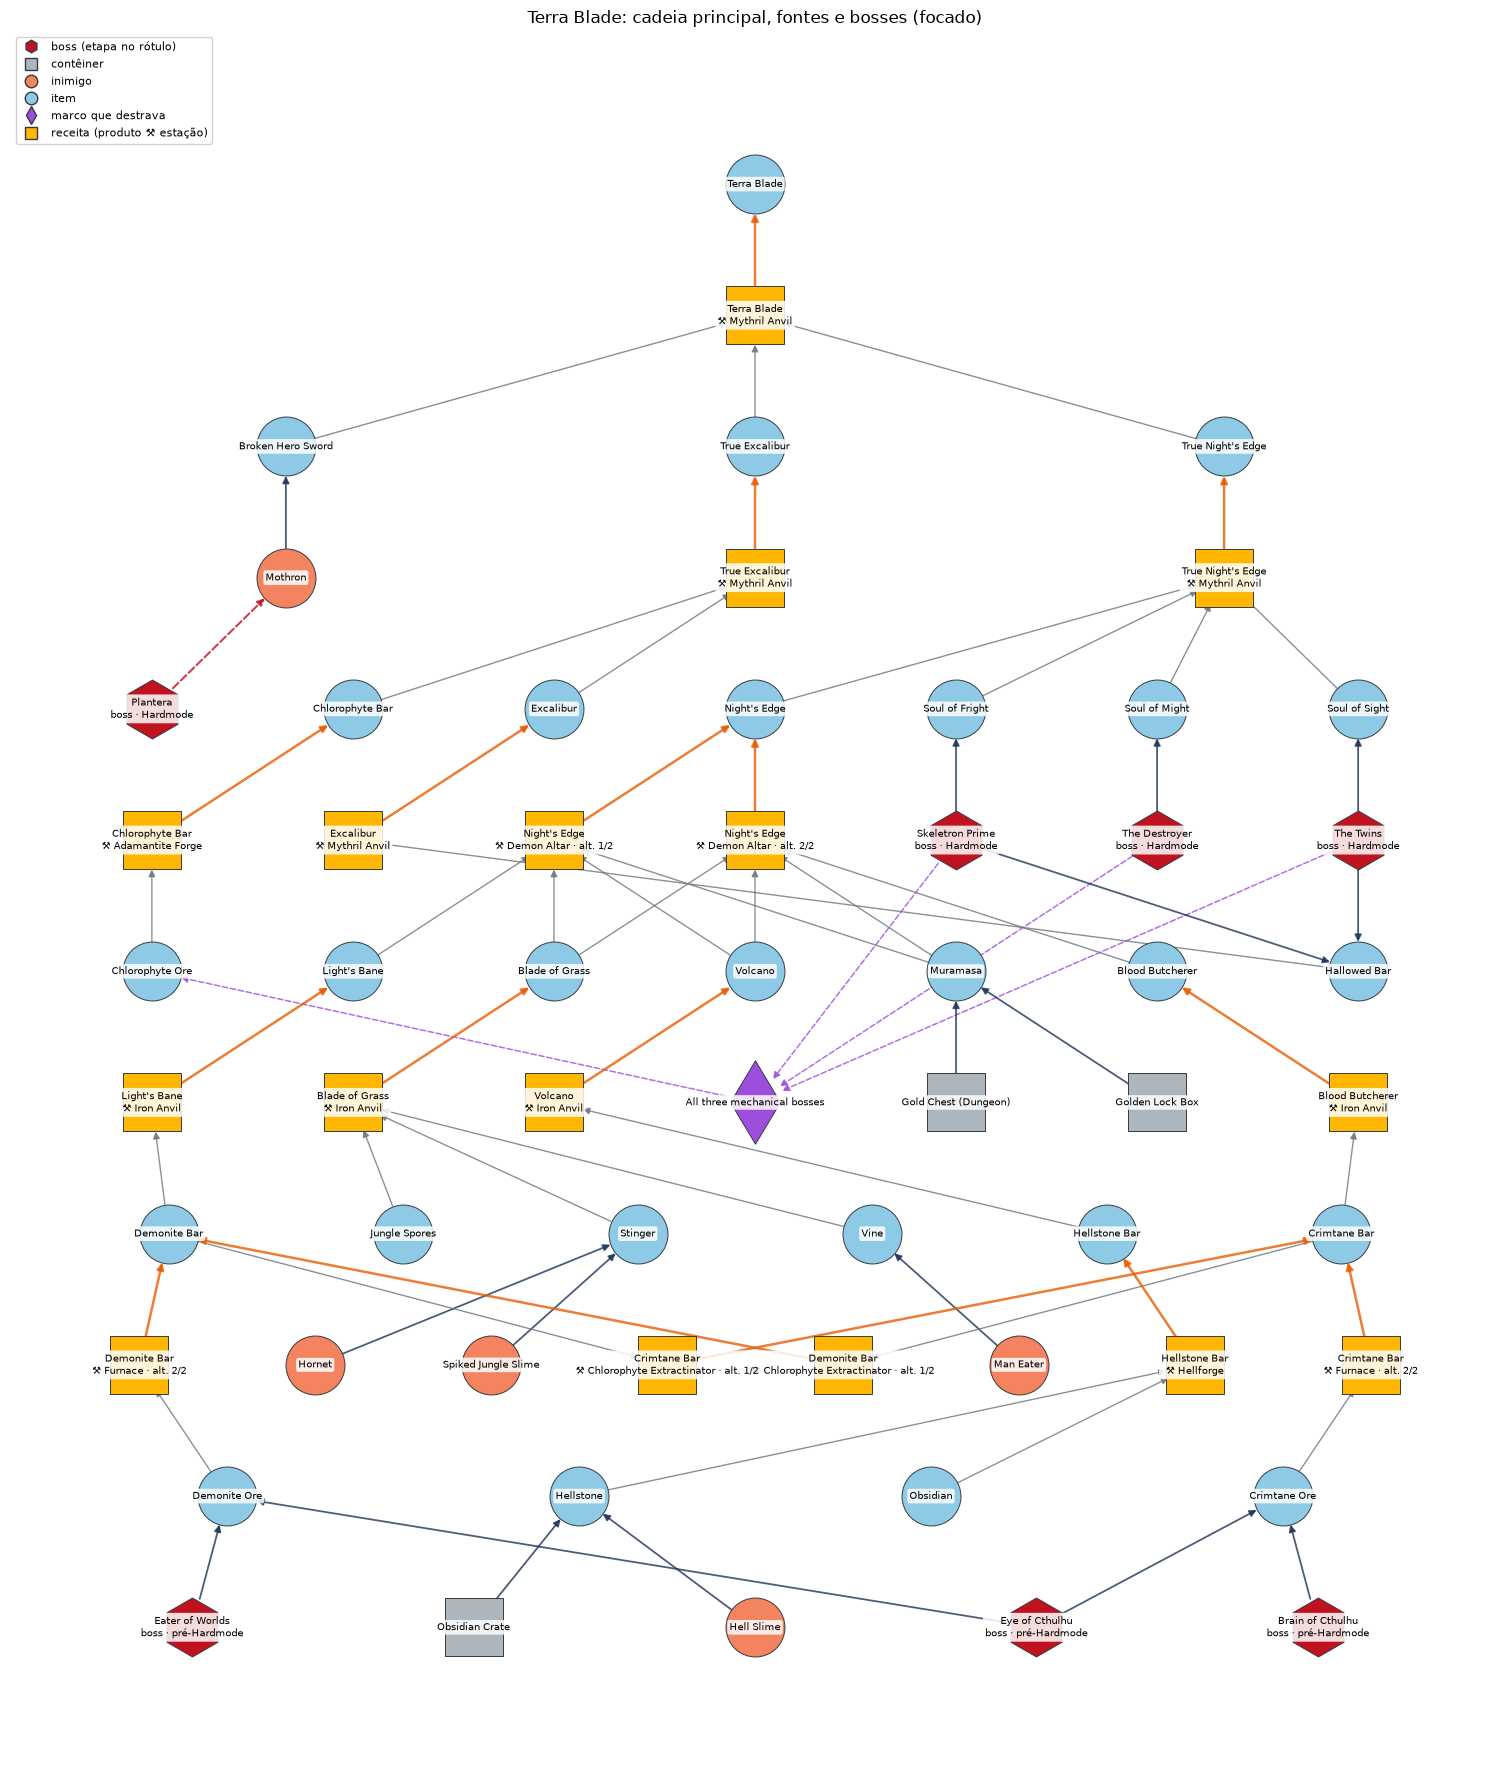

59 vértices em 12 camadas (a mais larga tem 8): 27 item, 16 receita, 7 boss, 5 inimigo, 3 contêiner, 1 marco que destrava.
Recorte com profundidade 5 e até 2 fontes por item; 4 rotas alternativas ficaram de fora do desenho, mas seguem em G.


In [13]:
def selecionar(item_key):
    """Modo detalhado: cadeia de fabricação inteira, rotas de cada item e bosses por trás delas."""
    alvo = f"item:{item_key}"
    if alvo not in G:
        raise KeyError(item_key)
    selected = {alvo}
    pending = [alvo]
    while pending:
        node = pending.pop()
        for source, _, aresta in G.in_edges(node, data=True):
            if aresta["relation"] in {"produz", "ingrediente"} and source not in selected:
                selected.add(source)
                pending.append(source)
    for item in [node for node in selected if G.nodes[node]["type"] == "item"]:
        for rota, _, aresta in G.in_edges(item, data=True):
            if aresta["relation"] not in {"obtém item", "vende"}:
                continue
            origens = list(G.predecessors(rota))
            # A sacola repete o drop do próprio boss; baú e vendedor são fontes distintas.
            if any(G.nodes[u]["type"] == "bag" for u in origens):
                continue
            selected.add(rota)
            selected.update(origens)
            for origem in origens:
                selected.update(u for u in G.predecessors(origem)
                                if G.nodes[u]["type"] in {"biome", "event"})
        if any(G.nodes[u]["type"] in {"recipe", "drop", "sale"} for u in G.predecessors(item)):
            continue
        for marco, _, aresta in G.in_edges(item, data=True):
            if aresta["relation"] != "disponibilidade estimada":
                continue
            atras = [u for u in G.predecessors(marco) if G.nodes[u]["type"] == "boss"]
            if atras:
                selected.add(marco)
                selected.update(atras)
    for origem in [node for node in list(selected) if G.nodes[node]["type"] in {"enemy", "container"}]:
        for boss, _, aresta in G.in_edges(origem, data=True):
            if aresta["relation"] == "habilita aparição":
                selected.add(boss)
    return alvo, G.subgraph(selected)

def mostrar_item(item_key, detalhado=False, profundidade=5, fontes_por_item=2):
    """Figura focada por padrão; `detalhado=True` desenha a cadeia inteira com os vértices de rota."""
    if detalhado:
        alvo, figura = selecionar(item_key)
        omitidas = 0
        titulo = f"{items[item_key]['name']}: cadeia completa, rotas e bosses (detalhado)"
    else:
        alvo, figura, omitidas = grafo_focado(item_key, profundidade, fontes_por_item)
        titulo = f"{items[item_key]['name']}: cadeia principal, fontes e bosses (focado)"
    total, fundo, largura = desenhar(figura, alvo, titulo)
    contagem = Counter(figura.nodes[node]["type"] for node in figura)
    # Ordem fixa por quantidade e depois por nome, para o resumo não mudar entre execuções.
    ordem = sorted(contagem.items(), key=lambda par: (-par[1], par[0]))
    resumo = ", ".join(f"{quantidade} {NOMES_TIPO.get(tipo, tipo).split(' (')[0]}"
                       for tipo, quantidade in ordem)
    print(f"{total} vértices em {fundo} camadas (a mais larga tem {largura}): {resumo}.")
    if not detalhado:
        print(f"Recorte com profundidade {profundidade} e até {fontes_por_item} fontes por item; "
              f"{omitidas} rotas alternativas ficaram de fora do desenho, mas seguem em G.")

mostrar_item("TerraBlade")

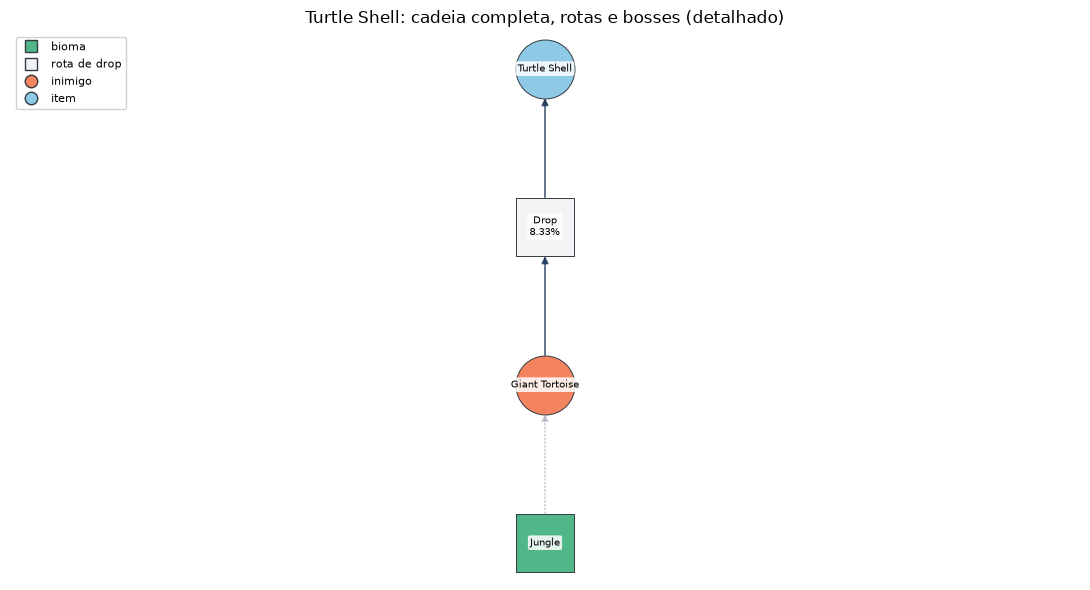

4 vértices em 4 camadas (a mais larga tem 1): 1 bioma, 1 rota de drop, 1 inimigo, 1 item.


In [14]:
# Modo detalhado num item pequeno: aqui a rota aparece como vértice e mostra a taxa do drop.
mostrar_item("TurtleShell", detalhado=True)

In [15]:
keys = ["TerraBlade", "TrueNightsEdge", "TrueExcalibur", "BrokenHeroSword", "ChlorophyteOre"]
display(pd.DataFrame([{"item": items[key]["name"], "marco estimado": milestones[items[key]["milestone"]]["name"],
                       "explicação da fonte": items[key].get("milestoneVia", "")} for key in keys]))
leaf = G.nodes["sale:LeafWings:0"]["dados"]
display(pd.DataFrame([{"rota": "Witch Doctor → Leaf Wings", "texto da oferta": leaf["text"],
                       "tokens": ", ".join(leaf["conditions"]), "bioma": ", ".join(leaf["biomes"])}]))
print("A receita de True Night's Edge exige as três almas; suas fontes são os três bosses mecânicos.")
print("Nesta oferta, o texto original expressa Hardmode E noite E Jungle E Plantera; outras rotas não herdam estas condições.")

,item,marco estimado,explicação da fonte
0,Terra Blade,Plantera,Crafted – needs Broken Hero Sword: Dropped by ...
1,True Night's Edge,All three mechanical bosses,"Crafted – needs Soul of Fright, Soul of Might ..."
2,True Excalibur,All three mechanical bosses,Crafted – needs Chlorophyte Bar → Chlorophyte ...
3,Broken Hero Sword,Plantera,Dropped by Mothron
4,Chlorophyte Ore,All three mechanical bosses,Mined (needs a Pickaxe Axe / Drax)


,rota,texto da oferta,tokens,bioma
0,Witch Doctor → Leaf Wings,"In Hardmode, during night, in a Jungle, when P...","hardmode, night, after-plantera",jungle


A receita de True Night's Edge exige as três almas; suas fontes são os três bosses mecânicos.
Nesta oferta, o texto original expressa Hardmode E noite E Jungle E Plantera; outras rotas não herdam estas condições.


## 5. Projeção acadêmica H

`H` contém somente itens envolvidos em receitas desktop. Cada opção de ingrediente é ligada ao produto da mesma receita; removemos laços e duplicatas. A projeção perde direção, receitas, quantidades, condições e lógica AND/OR, e não inclui marcos, bosses ou biomas. Daqui em diante, toda medida estrutural e toda comparação com redes sintéticas usam **apenas `H`** — nenhum número desta parte vem de `G`. A importância aqui é **topológica**, não mede importância para terminar o jogo.

In [16]:
H = nx.Graph()
for node, info in G.nodes(data=True):
    if info["type"] != "recipe":
        continue
    products = [v for _, v, edge in G.out_edges(node, data=True) if edge["relation"] == "produz"]
    for ingredient, _, edge in G.in_edges(node, data=True):
        if edge["relation"] == "ingrediente":
            for product in products:
                H.add_node(ingredient, name=G.nodes[ingredient]["name"])
                H.add_node(product, name=G.nodes[product]["name"])
                if ingredient != product:
                    H.add_edge(ingredient, product)
assert len(H) >= 300
componentes = sorted(nx.connected_components(H), key=len, reverse=True)
maior_componente = H.subgraph(componentes[0])
grau_medio = 2 * H.number_of_edges() / len(H)
print(f"H: {len(H):,} itens e {H.number_of_edges():,} arestas de fabricação.")
print(f"{len(componentes)} componentes conexas; a maior tem {len(maior_componente):,} vértices "
      f"({len(maior_componente)/len(H):.1%} do total).")
print(f"Grau médio {grau_medio:.2f}; densidade {nx.density(H):.5f}; clustering médio {nx.average_clustering(H):.4f}.")
print(f"O enunciado pede ao menos 300 vértices: H tem {len(H):,}.")

H: 3,773 itens e 6,692 arestas de fabricação.
62 componentes conexas; a maior tem 3,599 vértices (95.4% do total).
Grau médio 3.55; densidade 0.00094; clustering médio 0.0323.
O enunciado pede ao menos 300 vértices: H tem 3,773.


## 6. Métricas estruturais e distribuições

Três distribuições descrevem `H`: **grau** (quantas receitas ligam o item a outros itens), **intermediação** (quanto o item aparece em caminhos mínimos entre outros pares) e **clustering local** (quanto os vizinhos de um item também são vizinhos entre si).

A intermediação é **amostrada** com 256 origens sorteadas: o valor exato exigiria uma BFS a partir de cada um dos vértices. Grau, clustering e proximidade são exatos.

In [17]:
grau = pd.Series(dict(H.degree()), name="grau")
clustering = pd.Series(nx.clustering(H), name="clustering")
intermediacao = pd.Series(nx.betweenness_centrality(H, k=256, seed=SEED), name="intermediação")
proximidade = pd.Series(nx.closeness_centrality(H), name="proximidade")
metricas = pd.concat([grau, intermediacao, proximidade, clustering], axis=1)
metricas.insert(0, "item", [G.nodes[node]["name"] for node in metricas.index])

heterogeneidade = grau.std() / grau.mean()
razao_momentos = (grau ** 2).mean() / grau.mean()
print(f"Grau: média {grau.mean():.2f}, mediana {grau.median():.0f}, máximo {grau.max()} "
      f"({grau.max()/grau.mean():.0f}× a média).")
print(f"Coeficiente de variação do grau: {heterogeneidade:.2f}. Razão <k²>/<k> = {razao_momentos:.1f}.")
print(f"{(grau <= 2).mean():.1%} dos itens têm grau ≤ 2 e apenas {(grau >= 50).sum()} têm grau ≥ 50.")
print(f"Os 20 maiores hubs concentram {grau.nlargest(20).sum()/(2*H.number_of_edges()):.1%} das pontas de aresta.")

Grau: média 3.55, mediana 2, máximo 341 (96× a média).
Coeficiente de variação do grau: 3.12. Razão <k²>/<k> = 38.0.
71.8% dos itens têm grau ≤ 2 e apenas 22 têm grau ≥ 50.
Os 20 maiores hubs concentram 19.9% das pontas de aresta.


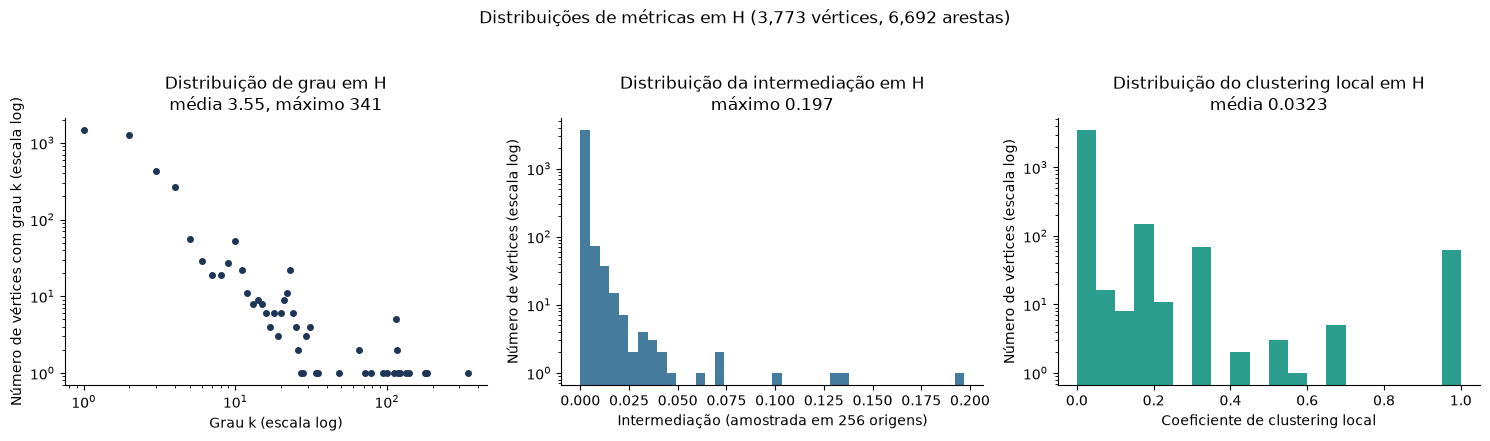

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

contagem = grau.value_counts().sort_index()
axes[0].scatter(contagem.index, contagem.values, s=16, color="#1d3557")
axes[0].set(xscale="log", yscale="log", xlabel="Grau k (escala log)",
            ylabel="Número de vértices com grau k (escala log)",
            title=f"Distribuição de grau em H\nmédia {grau.mean():.2f}, máximo {grau.max()}")

axes[1].hist(intermediacao, bins=40, color="#457b9d")
axes[1].set(yscale="log", xlabel="Intermediação (amostrada em 256 origens)",
            ylabel="Número de vértices (escala log)",
            title=f"Distribuição da intermediação em H\nmáximo {intermediacao.max():.3f}")

axes[2].hist(clustering, bins=20, color="#2a9d8f")
axes[2].set(yscale="log", xlabel="Coeficiente de clustering local",
            ylabel="Número de vértices (escala log)",
            title=f"Distribuição do clustering local em H\nmédia {clustering.mean():.4f}")

fig.suptitle(f"Distribuições de métricas em H ({len(H):,} vértices, {H.number_of_edges():,} arestas)", y=1.04)
plt.tight_layout()
plt.show()

In [19]:
clustering_hubs = clustering[grau >= 50].mean()
clustering_folhas = clustering[grau <= 4].mean()
sem_triangulo = (clustering == 0).mean()
display(Markdown(f"""**Como ler as três figuras**

- **Grau.** Em escala log-log a nuvem cai do canto superior esquerdo para a direita: {(grau <= 2).mean():.1%} dos
  itens têm grau ≤ 2 enquanto o maior hub tem grau {grau.max()}, cerca de {grau.max()/grau.mean():.0f} vezes a média
  ({grau.mean():.2f}). A rede é portanto **muito heterogênea**: quase tudo é periférico e poucos materiais
  concentram as ligações. O coeficiente de variação {heterogeneidade:.2f} e a razão <k²>/<k> = {razao_momentos:.1f}
  medem essa heterogeneidade sem depender da aparência do gráfico.
- **Intermediação.** A distribuição é fortemente assimétrica — note o eixo y em escala log. A maioria dos itens tem
  intermediação próxima de zero e nunca serve de passagem; um punhado chega a {intermediacao.max():.3f}, isto é,
  aparece em cerca de {intermediacao.max():.0%} dos caminhos mínimos amostrados. Esses vértices são
  **intermediários entre famílias de receitas diferentes**: móveis, equipamento, decoração e materiais de bioma só
  se alcançam uns aos outros passando por materiais comuns como barras, pedra e tochas.
- **Clustering local.** A média é {clustering.mean():.4f} e {sem_triangulo:.1%} dos itens têm clustering zero, ou
  seja, não participam de nenhum triângulo. Itens aparentados **não** formam grupos densos: uma receita liga
  ingrediente a produto, e dois ingredientes da mesma receita só ficam ligados entre si se existir outra receita
  entre eles. O clustering médio dos hubs (grau ≥ 50) é {clustering_hubs:.4f}, bem abaixo do clustering médio dos
  itens de grau ≤ 4 ({clustering_folhas:.4f}): os triângulos que existem estão na periferia, não em volta dos hubs."""))

**Como ler as três figuras**

- **Grau.** Em escala log-log a nuvem cai do canto superior esquerdo para a direita: 71.8% dos
  itens têm grau ≤ 2 enquanto o maior hub tem grau 341, cerca de 96 vezes a média
  (3.55). A rede é portanto **muito heterogênea**: quase tudo é periférico e poucos materiais
  concentram as ligações. O coeficiente de variação 3.12 e a razão <k²>/<k> = 38.0
  medem essa heterogeneidade sem depender da aparência do gráfico.
- **Intermediação.** A distribuição é fortemente assimétrica — note o eixo y em escala log. A maioria dos itens tem
  intermediação próxima de zero e nunca serve de passagem; um punhado chega a 0.197, isto é,
  aparece em cerca de 20% dos caminhos mínimos amostrados. Esses vértices são
  **intermediários entre famílias de receitas diferentes**: móveis, equipamento, decoração e materiais de bioma só
  se alcançam uns aos outros passando por materiais comuns como barras, pedra e tochas.
- **Clustering local.** A média é 0.0323 e 89.6% dos itens têm clustering zero, ou
  seja, não participam de nenhum triângulo. Itens aparentados **não** formam grupos densos: uma receita liga
  ingrediente a produto, e dois ingredientes da mesma receita só ficam ligados entre si se existir outra receita
  entre eles. O clustering médio dos hubs (grau ≥ 50) é 0.0017, bem abaixo do clustering médio dos
  itens de grau ≤ 4 (0.0335): os triângulos que existem estão na periferia, não em volta dos hubs.

## 7. Os três vértices mais importantes

**Por que estas três métricas.** Nenhuma medida isolada responde "qual vértice é mais importante", então combinamos três que medem coisas diferentes:

- **Grau** — importância local: quantas receitas distintas ligam o item a outros itens. Responde "quantos vizinhos".
- **Intermediação** — importância como ponte: com que frequência o item aparece em caminhos mínimos entre outros pares. Responde "quem fica no meio do caminho". É a única das três que enxerga a posição do vértice entre partes distintas da rede.
- **Proximidade** — importância como ponto de partida: o inverso da distância média até todos os outros vértices alcançáveis. Responde "de onde se chega rápido a todo o resto".

O **consenso** é a média dos três *ranks* (1 = melhor). Usar ranks e não os valores brutos evita que a escala de uma métrica domine as outras: grau é uma contagem na casa das centenas e intermediação é uma fração entre 0 e 1. Empates no consenso são desfeitos pelo grau. O clustering local aparece na tabela apenas como contexto e **não entra** na fórmula — ele mede coesão da vizinhança, não importância, e premia vértices minúsculos.

A intermediação é amostrada com 256 origens, então o consenso herda essa aproximação; vértices com valores muito próximos podem trocar de posição entre execuções com sementes diferentes.

In [20]:
ranks = metricas[["grau", "intermediação", "proximidade"]].rank(ascending=False, method="average")
metricas["consenso"] = ranks.mean(axis=1)
ordenados = metricas.sort_values(["consenso", "grau"], ascending=[True, False])
tabela = ordenados.head(6).copy()
tabela["rank grau"] = ranks.loc[tabela.index, "grau"].astype(int)
tabela["rank interm."] = ranks.loc[tabela.index, "intermediação"].astype(int)
tabela["rank prox."] = ranks.loc[tabela.index, "proximidade"].astype(int)
colunas = ["item", "grau", "intermediação", "proximidade", "clustering",
           "rank grau", "rank interm.", "rank prox.", "consenso"]
display(tabela[colunas].round(4))

top = ordenados.head(3)
top_nodes = list(top.index)
print("Os três vértices mais importantes de H:", ", ".join(top["item"]))
terceiro, quarto = top.iloc[2], ordenados.iloc[3]
if terceiro["consenso"] == quarto["consenso"]:
    print(f"Atenção ao empate: {terceiro['item']} e {quarto['item']} têm o mesmo consenso "
          f"({terceiro['consenso']:.2f}) e a 3ª posição foi decidida pelo grau "
          f"({int(terceiro['grau'])} contra {int(quarto['grau'])}).")
else:
    print(f"Margem para o 4º colocado ({quarto['item']}): consenso {quarto['consenso']:.2f} "
          f"contra {terceiro['consenso']:.2f} do 3º.")
print("A tabela mostra seis linhas para que a disputa pelas últimas posições fique visível.")

,item,grau,intermediação,proximidade,clustering,rank grau,rank interm.,rank prox.,consenso
item:Torch,Torch,341,0.1971,0.2759,0.0014,1,1,1,1.0000
item:IronBar,Iron Bar,183,0.0702,0.2576,0.0101,2,6,3,3.6667
item:LeadBar,Lead Bar,182,0.0716,0.2576,0.0103,3,5,4,4.0000
item:StoneBlock,Stone Block,140,0.1351,0.2543,0.0007,5,2,5,4.0000
item:Silk,Silk,177,0.1007,0.2524,0.0000,4,4,6,4.6667
item:Glass,Glass,115,0.1317,0.2612,0.0014,13,3,2,6.0000


Os três vértices mais importantes de H: Torch, Iron Bar, Lead Bar
Atenção ao empate: Lead Bar e Stone Block têm o mesmo consenso (4.00) e a 3ª posição foi decidida pelo grau (182 contra 140).
A tabela mostra seis linhas para que a disputa pelas últimas posições fique visível.


In [21]:
lideres = []
for metrica in ["grau", "intermediação", "proximidade", "clustering"]:
    melhor = metricas[metrica].idxmax()
    lideres.append({"métrica": metrica, "líder": metricas.loc[melhor, "item"],
                    "valor": metricas.loc[melhor, metrica], "grau do líder": int(grau[melhor])})
display(pd.DataFrame(lideres).round(4))

segundo_interm = metricas["intermediação"].nlargest(2).index[1]
segundo_prox = metricas["proximidade"].nlargest(2).index[1]
display(Markdown(f"""**Por que os rankings divergem.** Um mesmo vértice lidera grau, intermediação e proximidade
aqui — {metricas.loc[metricas['grau'].idxmax(), 'item']} —, mas a partir do segundo lugar as métricas discordam:

- O 2º em intermediação é **{metricas.loc[segundo_interm, 'item']}** (grau {int(grau[segundo_interm])},
  intermediação {metricas.loc[segundo_interm, 'intermediação']:.4f}), enquanto o 2º em grau é
  **{metricas.loc[grau.nlargest(2).index[1], 'item']}** (grau {int(grau.nlargest(2).iloc[1])}, intermediação
  {metricas.loc[grau.nlargest(2).index[1], 'intermediação']:.4f}). Ou seja: um item com menos vizinhos pode estar
  em muito mais caminhos mínimos, porque o que importa para a intermediação é *entre quem* ele fica, não *quantos*
  vizinhos tem.
- O 2º em proximidade é **{metricas.loc[segundo_prox, 'item']}**, que também não é o 2º em grau.
- O líder de clustering é um vértice de grau {int(grau[metricas['clustering'].idxmax()])} cujos vizinhos são
  vizinhos entre si, dando clustering 1. Isso confirma que clustering **não é** uma medida de importância: ele é
  trivialmente máximo em vértices minúsculos e quase nulo nos hubs.

Importância, portanto, depende da pergunta. Por isso o consenso usa três métricas e não uma."""))

,métrica,líder,valor,grau do líder
0,grau,Torch,341.0000,341
1,intermediação,Torch,0.1971,341
2,proximidade,Torch,0.2759,341
3,clustering,Giant Shelly Banner,1.0000,2


**Por que os rankings divergem.** Um mesmo vértice lidera grau, intermediação e proximidade
aqui — Torch —, mas a partir do segundo lugar as métricas discordam:

- O 2º em intermediação é **Stone Block** (grau 140,
  intermediação 0.1351), enquanto o 2º em grau é
  **Iron Bar** (grau 183, intermediação
  0.0702). Ou seja: um item com menos vizinhos pode estar
  em muito mais caminhos mínimos, porque o que importa para a intermediação é *entre quem* ele fica, não *quantos*
  vizinhos tem.
- O 2º em proximidade é **Glass**, que também não é o 2º em grau.
- O líder de clustering é um vértice de grau 2 cujos vizinhos são
  vizinhos entre si, dando clustering 1. Isso confirma que clustering **não é** uma medida de importância: ele é
  trivialmente máximo em vértices minúsculos e quase nulo nos hubs.

Importância, portanto, depende da pergunta. Por isso o consenso usa três métricas e não uma.

In [22]:
articulacoes = set(nx.articulation_points(H))

def receitas_que_usam(item_key):
    """Receitas de G que listam o item como ingrediente, direto ou por grupo de alternativas."""
    encontradas = []
    for indice, recipe in enumerate(recipes):
        if f"recipe:{indice}" not in G:
            continue
        for slot in recipe["ingredients"]:
            direto = slot.get("item") == item_key
            por_grupo = "group" in slot and item_key in groups[slot["group"]]["items"]
            if direto or por_grupo:
                encontradas.append({"indice": indice, "produto": recipe["result"],
                                    "estacoes": recipe["stations"],
                                    "grupo": slot["group"] if por_grupo else None})
                break
    return encontradas

def cartao_de_importancia(node):
    """Evidência bruta de um vértice: receitas, estações, vizinhos e efeito da remoção."""
    item_key = node.split(":", 1)[1]
    usos = receitas_que_usam(item_key)
    por_grupo = [uso for uso in usos if uso["grupo"]]
    estacoes = Counter(estacao for uso in usos for estacao in uso["estacoes"])
    vizinhos = sorted(G.nodes[v]["name"] for v in H[node])
    sem_ele = H.copy()
    sem_ele.remove_node(node)
    componentes_depois = nx.number_connected_components(sem_ele)
    maior_depois = len(max(nx.connected_components(sem_ele), key=len))
    display(Markdown(f"### {metricas.loc[node, 'item']} (`{node}`)"))
    print(f"Grau {int(grau[node])} | intermediação {intermediacao[node]:.4f} "
          f"(rank {int(ranks.loc[node, 'intermediação'])}) | proximidade {proximidade[node]:.4f} "
          f"(rank {int(ranks.loc[node, 'proximidade'])}) | clustering {clustering[node]:.4f}")
    print(f"É ingrediente de {len(usos)} receitas desktop em G, das quais {len(por_grupo)} o aceitam "
          f"por um grupo de ingredientes alternativos.")
    print("Estações mais frequentes dessas receitas: "
          + ", ".join(f"{estacao} ({quantidade})" for estacao, quantidade in estacoes.most_common(5)) + ".")
    print("Exemplos de vizinhos em H: " + ", ".join(vizinhos[:8]) + ".")
    print(f"Removendo só este vértice, H passa de {len(componentes):,} para {componentes_depois:,} componentes "
          f"e a maior cai de {len(maior_componente):,} para {maior_depois:,} vértices.")
    print(f"É ponto de articulação: {node in articulacoes}.")

for node in top_nodes:
    cartao_de_importancia(node)
    print()

### Torch (`item:Torch`)

Grau 341 | intermediação 0.1971 (rank 1) | proximidade 0.2759 (rank 1) | clustering 0.0014
É ingrediente de 349 receitas desktop em G, das quais 0 o aceitam por um grupo de ingredientes alternativos.
Estações mais frequentes dessas receitas: Work Bench (156), Iron Anvil (42), By Hand (36), Sky Mill (20), Ancient Manipulator (20).
Exemplos de vizinhos em H: Aetherium Candelabra, Aetherium Candle, Aetherium Chandelier, Aetherium Lamp, Aetherium Lantern, Aquarium Candelabra, Aquarium Candle, Aquarium Chandelier.
Removendo só este vértice, H passa de 62 para 63 componentes e a maior cai de 3,599 para 3,596 vértices.
É ponto de articulação: True.



### Iron Bar (`item:IronBar`)

Grau 183 | intermediação 0.0702 (rank 6) | proximidade 0.2576 (rank 3) | clustering 0.0101
É ingrediente de 186 receitas desktop em G, das quais 172 o aceitam por um grupo de ingredientes alternativos.
Estações mais frequentes dessas receitas: Sawmill (44), Work Bench (44), Iron Anvil (33), Sky Mill (9), Mythril Anvil (9).
Exemplos de vizinhos em H: Actuation Rod, Aetherium Chest, Aetherium Clock, Announcement Box, Aquarium Clock, Ash Wood Chest, Ash Wood Clock, Balloon Chest.
Removendo só este vértice, H passa de 62 para 72 componentes e a maior cai de 3,599 para 3,588 vértices.
É ponto de articulação: True.



### Lead Bar (`item:LeadBar`)

Grau 182 | intermediação 0.0716 (rank 5) | proximidade 0.2576 (rank 4) | clustering 0.0103
É ingrediente de 185 receitas desktop em G, das quais 172 o aceitam por um grupo de ingredientes alternativos.
Estações mais frequentes dessas receitas: Sawmill (44), Work Bench (44), Iron Anvil (33), Sky Mill (9), Mythril Anvil (9).
Exemplos de vizinhos em H: Actuation Rod, Aetherium Chest, Aetherium Clock, Announcement Box, Aquarium Clock, Ash Wood Chest, Ash Wood Clock, Balloon Chest.
Removendo só este vértice, H passa de 62 para 71 componentes e a maior cai de 3,599 para 3,589 vértices.
É ponto de articulação: True.



In [23]:
def familias_vizinhas(node, quantidade):
    """Última palavra do nome dos vizinhos: revela as famílias de produto que usam o item."""
    familias = Counter(G.nodes[vizinho]["name"].rsplit(" ", 1)[-1] for vizinho in H[node])
    return familias.most_common(quantidade)

for node in top_nodes:
    familias = familias_vizinhas(node, 6)
    print(f"{metricas.loc[node, 'item']}: "
          + ", ".join(f"{quantidade}× …{familia}" for familia, quantidade in familias))
print()
print("A última palavra do nome agrupa os vizinhos por família de móvel ou equipamento.")
print("Terraria repete o mesmo conjunto de móveis para dezenas de materiais temáticos, e cada cópia")
print("da família exige o mesmo material comum. É esse mecanismo que fabrica os hubs de H.")

Torch: 62× …Lantern, 62× …Chandelier, 60× …Candle, 57× …Lamp, 57× …Candelabra, 20× …Torch
Iron Bar: 64× …Chest, 61× …Clock, 5× …Rack, 4× …Plate, 2× …Bathtub, 2× …Fence
Lead Bar: 64× …Chest, 61× …Clock, 5× …Rack, 4× …Plate, 2× …Bathtub, 2× …Door

A última palavra do nome agrupa os vizinhos por família de móvel ou equipamento.
Terraria repete o mesmo conjunto de móveis para dezenas de materiais temáticos, e cada cópia
da família exige o mesmo material comum. É esse mecanismo que fabrica os hubs de H.


### 7.1 Justificativa individual

**Torch — o hub de iluminação.** O grau altíssimo não vem de poder de combate: vem de repetição. Terraria tem dezenas de conjuntos temáticos de mobiliário (Lesion, Steampunk, Flesh, Glass, Honey, Frozen, Bone, Living Wood…) e **cada conjunto repete as mesmas cinco peças de iluminação** — Lantern, Candle, Lamp, Candelabra e Chandelier. Todas pedem uma Torch. É por isso que os vizinhos de Torch se agrupam em famílias de ~60 itens com o mesmo sufixo, e por isso ele é ingrediente de mais de 340 receitas distintas, espalhadas por estações que vão da Work Bench do primeiro minuto de jogo até o Ancient Manipulator do fim de jogo. Como essas receitas atravessam todas as etapas do jogo, Torch fica **no meio do caminho entre regiões da rede que não se tocam de outro modo**: a família de móveis do Dungeon e a do Jungle Temple só se alcançam via material comum. Daí ele liderar também intermediação e proximidade. Em Terraria, Torch é um item trivial e barato — o que a centralidade mede aqui é **ubiquidade de receita**, não dificuldade nem poder.

**Iron Bar — a barra básica que serve a dois mundos.** Iron Bar aparece em receitas de duas naturezas distintas. A primeira é mobiliário: cada conjunto temático tem um **Chest** e um **Clock**, e ambos exigem Iron Bar — daí as duas famílias de ~60 vizinhos cada, fabricadas em Sawmill e Work Bench. A segunda é a progressão inicial de equipamento: Iron Anvil, Iron Pickaxe, Iron Broadsword, Iron Bow, Iron Helmet, Iron Chainmail, Iron Greaves, fabricados na Iron Anvil. **É essa dupla natureza que o mantém entre os dez maiores em intermediação**, mesmo tendo pouco mais da metade dos vizinhos do primeiro colocado: ele é um dos poucos pontos onde a parte decorativa da rede encontra a parte de equipamento. Note, porém, que a tabela acima mostra Stone Block e Glass **acima** dele em intermediação com grau menor — Iron Bar entra no pódio pelo conjunto das três métricas, não por liderar alguma delas. Removê-lo sozinho já desprende um punhado de itens da maior componente. Em Terraria, Iron Bar é um material de pré-Hardmode, obtido fundindo Iron Ore — ou seja, um item inicial e barato ocupa posição estrutural central porque o jogo o reaproveita o tempo todo.

**Lead Bar — o mesmo papel, pelo outro minério.** Lead Bar tem praticamente os mesmos números de Iron Bar, e isso **não é coincidência**: é consequência direta do grupo de ingredientes alternativos `Any Iron Bar`, que contém exatamente os dois. Toda receita que aceita o grupo gera, no modelo, uma aresta para Iron Bar **e** uma para Lead Bar, de modo que os dois herdam a mesma vizinhança. O que os separa são apenas as receitas que citam um deles nominalmente: o equipamento de tier Iron de um lado e o de tier Lead do outro. Os dois ainda são vizinhos **entre si**, porque o Chlorophyte Extractinator converte uma barra na outra. Em Terraria isso corresponde a um fato de geração de mundo: cada mundo sorteia Iron **ou** Lead, e o jogo garante que quase toda receita aceite os dois. A leitura honesta, portanto, é que **Iron Bar e Lead Bar não são dois hubs independentes — são duas faces do mesmo papel estrutural**. A célula seguinte mede o tamanho dessa sobreposição, e logo abaixo indicamos qual seria o terceiro hub de papel realmente distinto.

In [24]:
iron, lead = "item:IronBar", "item:LeadBar"
vizinhos_iron = set(H[iron])
vizinhos_lead = set(H[lead])
comuns = vizinhos_iron & vizinhos_lead
grupo = groups["Any Iron Bar"]["items"]
usa_grupo = sum(1 for uso in receitas_que_usam("IronBar") if uso["grupo"] == "Any Iron Bar")
print(f"Grupo 'Any Iron Bar' = {grupo}; {usa_grupo} receitas desktop o usam.")
print(f"Iron Bar tem {len(vizinhos_iron)} vizinhos, Lead Bar tem {len(vizinhos_lead)}; "
      f"{len(comuns)} são compartilhados ({len(comuns)/len(vizinhos_iron):.1%} dos de Iron Bar).")
print("Só de Iron Bar: " + ", ".join(sorted(G.nodes[v]["name"] for v in vizinhos_iron - vizinhos_lead)))
print("Só de Lead Bar: " + ", ".join(sorted(G.nodes[v]["name"] for v in vizinhos_lead - vizinhos_iron)))

distintos = [node for node in ordenados.index[:8] if node not in {iron, lead}]
alternativo = distintos[1]
print()
print(f"Se o critério exigisse três papéis estruturais distintos, o terceiro seria "
      f"{metricas.loc[alternativo, 'item']} (grau {int(grau[alternativo])}, "
      f"intermediação {intermediacao[alternativo]:.4f}, consenso {metricas.loc[alternativo, 'consenso']:.2f}), "
      f"que serve a outra família de receitas.")
print("Alta centralidade não significa item obrigatório: a maioria dessas receitas é de decoração,")
print("e nenhuma delas é exigida para derrotar qualquer boss.")

Grupo 'Any Iron Bar' = ['IronBar', 'LeadBar']; 172 receitas desktop o usam.
Iron Bar tem 183 vizinhos, Lead Bar tem 182; 168 são compartilhados (91.8% dos de Iron Bar).
Só de Iron Bar: Iron Anvil, Iron Axe, Iron Bow, Iron Broadsword, Iron Chainmail, Iron Door, Iron Fence, Iron Greaves, Iron Hammer, Iron Helmet, Iron Ore, Iron Pickaxe, Iron Shortsword, Lead Bar, Wrought Iron Fence
Só de Lead Bar: Iron Bar, Lead Anvil, Lead Axe, Lead Bow, Lead Broadsword, Lead Chainmail, Lead Door, Lead Fence, Lead Greaves, Lead Hammer, Lead Helmet, Lead Ore, Lead Pickaxe, Lead Shortsword

Se o critério exigisse três papéis estruturais distintos, o terceiro seria Stone Block (grau 140, intermediação 0.1351, consenso 4.00), que serve a outra família de receitas.
Alta centralidade não significa item obrigatório: a maioria dessas receitas é de decoração,
e nenhuma delas é exigida para derrotar qualquer boss.


## 8. Comparação com redes sintéticas

Quatro modelos, todos com o **mesmo número de vértices de H**:

| Modelo | Construção | Parâmetro | Arestas |
|---|---|---|---|
| **ER** (Erdős–Rényi) | sorteia arestas uniformemente | `gnm_random_graph(n, m)` | **exatamente m** |
| **WS** (Watts–Strogatz) | anel regular de grau `k` com religação de probabilidade β | `k` par, β = 0,1 | `n·k/2`, só múltiplos de `n` |
| **BA** (Barabási–Albert) | cresce por ligação preferencial | `m₀` arestas por vértice novo | `m₀·(n−m₀)`, só múltiplos aproximados de `n` |
| **Nulo de graus** | embaralha H preservando o grau de cada vértice | `double_edge_swap` | **exatamente m** |

**Por que ER e o nulo de graus batem o número de arestas e WS e BA não.** ER e o nulo recebem `m` diretamente. WS e BA constroem a rede a partir de um parâmetro inteiro por vértice: WS só produz grau médio par e BA só produz grau médio próximo de `2·m₀`. Como o grau médio de H não é inteiro, **nenhum valor de `k` ou de `m₀` reproduz `m` exatamente**. Escolhemos o inteiro mais próximo e **não removemos arestas à força**, porque apagar arestas de um anel WS ou de uma árvore de crescimento BA destruiria justamente a estrutura que o modelo existe para representar. A consequência é que WS e BA ficam com grau médio um pouco maior que o de H; a tabela mostra a diferença, e é por isso que ela inclui a coluna de grau médio.

**Cada modelo isola uma hipótese.** ER é a referência de aleatoriedade pura. WS é a referência de small-world clássico: caminhos curtos com clustering alto. BA é a referência de rede livre de escala por ligação preferencial. O nulo de graus é a referência mais exigente: ele tem **exatamente a mesma sequência de graus de H**, logo qualquer diferença entre H e o nulo não pode ser explicada só pelos hubs.

**Distâncias são estimadas.** A distância média é calculada por BFS a partir de 256 origens sorteadas dentro da maior componente, não por todos os pares. São **estimativas**, não medidas exatas; a célula seguinte compara a estimativa de H com o valor exato para mostrar o erro envolvido. Três realizações independentes por modelo reduzem a dependência de um sorteio específico.

In [25]:
def resumo(graph, seed):
    """Métricas estruturais de um grafo; a distância média é estimada por BFS amostrada."""
    componente = graph.subgraph(max(nx.connected_components(graph), key=len))
    origens = random.Random(seed).sample(list(componente), min(256, len(componente)))
    distancias = []
    for origem in origens:
        alcancadas = nx.single_source_shortest_path_length(componente, origem)
        distancias.append(sum(alcancadas.values()) / (len(componente) - 1))
    return {"vértices": graph.number_of_nodes(), "arestas": graph.number_of_edges(),
            "grau médio": 2 * graph.number_of_edges() / graph.number_of_nodes(),
            "clustering médio": nx.average_clustering(graph),
            "distância média (estimada)": float(np.mean(distancias)),
            "fração na maior componente": len(componente) / graph.number_of_nodes()}

n = len(H)
m = H.number_of_edges()
k_ws = max(2, 2 * round(m / n))
m_ba = max(1, round(m / n))
trocas = 10 * m

def gerar(nome, seed):
    if nome == "ER":
        return nx.gnm_random_graph(n, m, seed=seed)
    if nome == "WS":
        return nx.watts_strogatz_graph(n, k_ws, .1, seed=seed)
    if nome == "BA":
        return nx.barabasi_albert_graph(n, m_ba, seed=seed)
    embaralhado = H.copy()
    nx.double_edge_swap(embaralhado, nswap=trocas, max_tries=200 * m, seed=seed)
    return embaralhado

linhas = [{"modelo": "Terraria (H)", "realização": 0, **resumo(H, SEED)}]
for repeticao in range(3):
    seed = SEED + repeticao
    for nome in ["ER", "WS", "BA", "Nulo de graus"]:
        grafo = gerar(nome, seed)
        linhas.append({"modelo": nome, "realização": repeticao, **resumo(grafo, seed)})
        del grafo
comparacao = pd.DataFrame(linhas)
medias = comparacao.drop(columns="realização").groupby("modelo").mean()
medias = medias.reindex(["Terraria (H)", "ER", "WS", "BA", "Nulo de graus"])
display(medias.round(4))
print(f"Parâmetros: ER com m={m:,} arestas exatas; WS com k={k_ws} e β=0,1; BA com m₀={m_ba}; "
      f"nulo com {trocas:,} trocas de arestas. Semente base {SEED}.")

,vértices,arestas,grau médio,clustering médio,distância média (estimada),fração na maior componente
modelo,,,,,,
Terraria (H),3773.0,6692.0,3.5473,0.0323,5.5397,0.9539
ER,3773.0,6692.0,3.5473,0.0007,6.5422,0.9667
WS,3773.0,7546.0,4.0000,0.3705,10.7979,1.0000
BA,3773.0,7542.0,3.9979,0.0095,4.6369,1.0000
Nulo de graus,3773.0,6692.0,3.5473,0.0449,4.0820,0.9459


Parâmetros: ER com m=6,692 arestas exatas; WS com k=4 e β=0,1; BA com m₀=2; nulo com 66,920 trocas de arestas. Semente base 42.


In [ ]:
desvios = comparacao[comparacao["modelo"] != "Terraria (H)"].groupby("modelo")[
    ["clustering médio", "distância média (estimada)"]].std()
print("Desvio-padrão entre as três realizações de cada modelo:")
display(desvios.round(4))

distancia_exata = nx.average_shortest_path_length(maior_componente)
estimativa_H = medias.loc["Terraria (H)", "distância média (estimada)"]
print(f"Calibração da estimativa: a distância média exata na maior componente de H é "
      f"{distancia_exata:.4f} arestas; a estimativa com 256 origens deu {estimativa_H:.4f} "
      f"(erro de {abs(estimativa_H - distancia_exata)/distancia_exata:.1%}).")
print("O valor exato é usado só aqui, como aferição; a tabela acima mantém a estimativa amostrada")
print("para que H e os modelos sintéticos sejam medidos exatamente do mesmo jeito.")

Desvio-padrão entre as três realizações de cada modelo:


,clustering médio,distância média (estimada)
modelo,,
BA,0.0016,0.0502
ER,0.0001,0.0315
Nulo de graus,0.0034,0.0425
WS,0.0061,0.1674


In [ ]:
def ccdf(graph):
    """P(K ≥ k): distribuição acumulada complementar do grau, mais estável que o histograma na cauda."""
    graus = np.sort([valor for _, valor in graph.degree()])
    return graus, 1 - np.arange(len(graus)) / len(graus)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

CORES_MODELO = {"Terraria (H)": "#1d3557", "ER": "#e76f51", "BA": "#2a9d8f", "WS": "#e9c46a"}
exemplos = {"Terraria (H)": H}
for nome in ["ER", "BA", "WS"]:
    exemplos[nome] = gerar(nome, SEED)
for nome, grafo in exemplos.items():
    eixo_x, eixo_y = ccdf(grafo)
    axes[0].plot(eixo_x, eixo_y, label=nome, color=CORES_MODELO[nome], linewidth=1.6)
axes[0].set(xscale="log", yscale="log", xlabel="Grau k (escala log)",
            ylabel="Fração de vértices com grau ≥ k (escala log)",
            title="Distribuição de grau acumulada:\nH contra ER, BA e WS")
axes[0].legend(fontsize=8)

medias["clustering médio"].plot.bar(ax=axes[1], color="#457b9d")
axes[1].set(xlabel="", ylabel="Clustering médio", title="Clustering médio por modelo")

medias["distância média (estimada)"].plot.bar(ax=axes[2], color="#e9c46a")
axes[2].set(xlabel="", ylabel="Distância média (arestas, estimada)",
            title="Distância média na maior componente")

for eixo in axes[1:]:
    eixo.tick_params(axis="x", rotation=30)
    for rotulo in eixo.get_xticklabels():
        rotulo.set_ha("right")
fig.suptitle(f"H ({n:,} vértices, {m:,} arestas) contra redes sintéticas de mesmo tamanho", y=1.04)
plt.tight_layout()
plt.show()

In [ ]:
graus_modelos = {}
for nome, grafo in exemplos.items():
    graus_modelos[nome] = np.array([valor for _, valor in grafo.degree()])
resumo_graus = pd.DataFrame([
    {"modelo": nome, "grau médio": valores.mean(), "grau máximo": int(valores.max()),
     "coef. de variação": valores.std() / valores.mean(),
     "<k²>/<k>": (valores ** 2).mean() / valores.mean()}
    for nome, valores in graus_modelos.items()]).set_index("modelo")
display(resumo_graus.round(3))

display(Markdown(f"""**Quatro coisas diferentes que a figura da esquerda pode mostrar — e qual é o caso aqui.**

1. **Distribuição homogênea:** todos os vértices têm grau parecido e a curva despenca logo depois da média. É o caso
   de **WS** (coeficiente de variação {resumo_graus.loc['WS', 'coef. de variação']:.2f}, grau máximo
   {resumo_graus.loc['WS', 'grau máximo']}) e, em menor escala, de **ER** ({resumo_graus.loc['ER', 'coef. de variação']:.2f},
   máximo {resumo_graus.loc['ER', 'grau máximo']}). Nenhum dos dois produz hubs.
2. **Rede heterogênea com hubs:** existem vértices com grau muitas vezes maior que a média. É o caso de **H**
   (coeficiente de variação {resumo_graus.loc['Terraria (H)', 'coef. de variação']:.2f}, grau máximo
   {resumo_graus.loc['Terraria (H)', 'grau máximo']} contra média
   {resumo_graus.loc['Terraria (H)', 'grau médio']:.2f}) — e H é **mais** heterogênea que o próprio BA
   ({resumo_graus.loc['BA', 'coef. de variação']:.2f}).
3. **Cauda pesada:** a curva acumulada decai devagar em log-log, sem corte abrupto. H e BA mostram isso; ER e WS não.
4. **Lei de potência verificada estatisticamente:** exigiria estimar o expoente por máxima verossimilhança, achar o
   `k` mínimo a partir do qual a lei vale e rodar um teste de aderência com rede sintética de comparação.
   **Isso não foi feito aqui**, e a curva de H nem sequer é uma reta: ela tem um patamar visível perto de k ≈ 115
   e um valor isolado muito acima do resto.

Os três primeiros pontos estão **demonstrados** pelos números. O quarto **não**. Uma cauda pesada é compatível com
uma lei de potência, mas não a prova: patamares e outliers como os de H também aparecem em distribuições que não
são leis de potência."""))

## 9. A rede é livre de escala, small-world ou aleatória?

As três hipóteses são tratadas separadamente, cada uma com o critério que a define e o modelo sintético que serve de referência. Todos os números abaixo vêm da execução atual.

In [ ]:
clustering_H = medias.loc["Terraria (H)", "clustering médio"]
clustering_ER = medias.loc["ER", "clustering médio"]
clustering_nulo = medias.loc["Nulo de graus", "clustering médio"]
clustering_WS = medias.loc["WS", "clustering médio"]
distancia_H = medias.loc["Terraria (H)", "distância média (estimada)"]
distancia_ER = medias.loc["ER", "distância média (estimada)"]
distancia_nulo = medias.loc["Nulo de graus", "distância média (estimada)"]
distancia_WS = medias.loc["WS", "distância média (estimada)"]

evidencias = pd.DataFrame([
    {"critério": "clustering de H ÷ clustering de ER", "valor": clustering_H / clustering_ER,
     "esperado se H fosse aleatória": 1.0},
    {"critério": "clustering de H ÷ clustering do nulo de graus", "valor": clustering_H / clustering_nulo,
     "esperado se H fosse aleatória": 1.0},
    {"critério": "distância de H ÷ distância de ER", "valor": distancia_H / distancia_ER,
     "esperado se H fosse aleatória": 1.0},
    {"critério": "distância de H ÷ distância do nulo de graus", "valor": distancia_H / distancia_nulo,
     "esperado se H fosse aleatória": 1.0},
    {"critério": "coef. de variação do grau de H ÷ o de ER",
     "valor": resumo_graus.loc["Terraria (H)", "coef. de variação"] / resumo_graus.loc["ER", "coef. de variação"],
     "esperado se H fosse aleatória": 1.0},
])
display(evidencias.round(3))
print(f"Referência de small-world clássico (WS): clustering {clustering_WS:.4f} e distância {distancia_WS:.2f}.")
print(f"Fração de H na maior componente: {len(maior_componente)/len(H):.1%}, em "
      f"{len(componentes)} componentes.")

In [ ]:
display(Markdown(f"""### 9.1 H é uma rede aleatória?

**Não.** Com o mesmo número de vértices e exatamente o mesmo número de arestas, o grafo ER difere de H em todos os
critérios medidos:

- **Grau.** ER tem grau máximo {resumo_graus.loc['ER', 'grau máximo']} e coeficiente de variação
  {resumo_graus.loc['ER', 'coef. de variação']:.2f}; H tem máximo {resumo_graus.loc['Terraria (H)', 'grau máximo']}
  e coeficiente {resumo_graus.loc['Terraria (H)', 'coef. de variação']:.2f}, ou seja,
  {resumo_graus.loc['Terraria (H)', 'coef. de variação'] / resumo_graus.loc['ER', 'coef. de variação']:.0f} vezes
  mais heterogênea. Um grafo aleatório simplesmente não produz um vértice com grau {grau.max()}.
- **Clustering.** H tem {clustering_H:.4f} contra {clustering_ER:.4f} de ER — cerca de
  {clustering_H / clustering_ER:.0f} vezes mais. O clustering de H é baixo em termos absolutos, mas é muito alto
  comparado ao acaso.
- **Distância.** H estima {distancia_H:.2f} arestas e ER {distancia_ER:.2f}: H é um pouco **mais curta** que o
  acaso, graças aos hubs que servem de atalho.
- **Conectividade.** H tem {len(componentes)} componentes e {len(maior_componente)/len(H):.1%} dos vértices na
  maior; ER com os mesmos parâmetros fica com {medias.loc['ER', 'fração na maior componente']:.1%}. H é mais
  fragmentada: há famílias de receitas que não se ligam a nada.

### 9.2 H é livre de escala?

**Não demonstrado.** O que está demonstrado é a **heterogeneidade**: H tem hubs e cauda pesada, com razão
<k²>/<k> = {razao_momentos:.1f} contra grau médio {grau.mean():.2f}, e é até mais heterogênea que o BA gerado como
referência. Mas a existência de hubs **não é suficiente** para afirmar lei de potência, por três motivos:

1. Hubs aparecem em várias distribuições de cauda pesada — log-normal, exponencial esticada, mistura de
   distribuições — que não são leis de potência.
2. A distribuição de H tem estrutura que uma lei de potência não prevê: um **patamar** de vários itens com grau
   próximo de 115 (as madeiras temáticas, que compartilham o mesmo conjunto de móveis) e um **outlier isolado**
   em {grau.max()}, muito distante do segundo colocado ({int(grau.nlargest(2).iloc[1])}).
3. Afirmar lei de potência exigiria estimar o expoente por máxima verossimilhança, escolher o `k` mínimo de
   validade e aplicar um teste de aderência. **Esse teste não foi feito** e seria preciso bibliotecas específicas.

O mecanismo que gera os hubs em H também não é ligação preferencial: hubs não surgem porque "o rico fica mais
rico", e sim porque o jogo **repete o mesmo conjunto de móveis para dezenas de materiais temáticos**, e cada cópia
exige o mesmo material comum. Isso é um gerador combinatório, não um processo de crescimento preferencial.

### 9.3 H é small-world?

**Não no sentido forte — e a resposta muda conforme o grafo de comparação, que é justamente o ponto.** O critério
clássico exige duas coisas ao mesmo tempo: clustering muito maior que o do grafo aleatório **e** distância média
parecida com a dele. A pergunta decisiva é *qual* grafo aleatório serve de referência.

- **Contra ER, H passa:** clustering {clustering_H / clustering_ER:.0f}× maior e distância
  {distancia_H / distancia_ER:.2f}× a de ER, isto é, até mais curta. Pelo teste ingênuo, H seria small-world.
- **Contra o nulo de graus, H não passa em nenhum dos dois critérios:** o nulo tem **exatamente a mesma sequência
  de graus** de H, e mesmo assim chega a clustering {clustering_nulo:.4f}, ou seja, H tem razão
  {clustering_H / clustering_nulo:.2f} — **abaixo de 1**. O clustering de H não é um excesso de coesão: ele é
  inteiramente explicado pela sua distribuição de graus, e fica até um pouco menor que o esperado para ela. A
  distância conta a mesma história: o nulo chega a {distancia_nulo:.2f} arestas contra {distancia_H:.2f} de H, isto
  é, **H é {distancia_H / distancia_nulo:.2f}× mais longa** que a rede aleatória com os seus próprios graus. Nem a
  coesão nem os atalhos de H superam o que a sequência de graus já garante sozinha.
- **Contra WS, a rede small-world de manual, H não se parece:** WS tem clustering {clustering_WS:.4f}
  ({clustering_WS / clustering_H:.0f}× o de H) e distância {distancia_WS:.1f} ({distancia_WS / distancia_H:.1f}× a
  de H). São perfis opostos: WS é muito coesa e lenta, H é pouco coesa e rápida.

A leitura honesta: **as distâncias de H são pequenas em termos absolutos** — {distancia_H:.2f} arestas para
{len(maior_componente):,} vértices —, mas nem elas nem o clustering são um ganho *sobre o que a distribuição de
graus já explica*. O que torna H "pequena" são os hubs, não triângulos entre itens aparentados, e um modelo que
copie apenas os graus de H reproduz — e supera — os dois efeitos. Por isso o rótulo "small-world" não se sustenta
no sentido estrito.

### 9.4 Conclusão da classificação

| Afirmação | Situação |
|---|---|
| H **não** é uma rede aleatória do tipo ER | **sustentada** — difere em grau, clustering, distância e conectividade |
| H é fortemente **heterogênea**, com hubs e cauda pesada | **sustentada** — CV {resumo_graus.loc['Terraria (H)', 'coef. de variação']:.2f}, <k²>/<k> = {razao_momentos:.1f} |
| H tem **caminhos curtos** como uma rede aleatória | **sustentada** — {distancia_H:.2f} contra {distancia_ER:.2f} de ER |
| Os caminhos de H são curtos **além** do que seus graus explicam | **refutada** — o nulo de graus chega a {distancia_nulo:.2f} |
| H é **livre de escala** (lei de potência) | **não demonstrada** — sem teste estatístico, e a cauda tem patamar e outlier |
| H é **small-world** no sentido forte | **refutada** — nem clustering nem distância superam o nulo que preserva os graus |
| H tem **clustering alto** em termos absolutos | **refutada** — {clustering_H:.4f} é baixo; só parece alto ao lado de ER |

**Em uma frase:** a rede de fabricação do Terraria é uma rede **heterogênea e de caminhos curtos, dominada por
hubs**, que não é aleatória, mas cujas evidências **não bastam** para chamá-la de livre de escala nem de small-world
no sentido estrito. Forçar uma das três categorias seria afirmar mais do que os dados mostram."""))

## 10. Robustez, difusão, preservação e navegação

Quatro perguntas do enunciado, todas respondidas sobre `H`. A medida de referência é sempre a **maior componente conexa em relação ao número original de vértices de H** — o denominador não muda quando removemos vértices, de modo que as curvas são diretamente comparáveis.

### 10.1 Robustez a falhas

Três cenários, com o mesmo conjunto de frações removidas:

- **Falha aleatória:** sorteia os vértices a remover, média de cinco ordens independentes.
- **Ataque estático por grau:** remove na ordem do grau **no grafo original**, calculada uma única vez antes de começar.
- **Ataque adaptativo por grau:** a cada etapa recalcula o grau no que sobrou e remove os maiores de então. É mais caro e mais destrutivo, porque acompanha a mudança de quem é hub depois de cada remoção.

In [ ]:
fracoes = np.linspace(0, .5, 11)

def curva_por_ordem(ordem):
    """Maior componente restante ao remover vértices numa ordem fixa, decidida antes do início."""
    grafo = H.copy()
    valores = []
    removidos = 0
    for fracao in fracoes:
        alvo = int(fracao * len(H))
        grafo.remove_nodes_from(ordem[removidos:alvo])
        removidos = alvo
        maior = max(nx.connected_components(grafo), key=len, default=set())
        valores.append(len(maior) / len(H))
    return np.array(valores)

def curva_adaptativa():
    """Recalcula o grau a cada etapa e remove os maiores do grafo que restou."""
    grafo = H.copy()
    valores = []
    removidos = 0
    for fracao in fracoes:
        alvo = int(fracao * len(H))
        quantos = alvo - removidos
        if quantos > 0:
            ordem_atual = sorted(grafo, key=grafo.degree, reverse=True)
            grafo.remove_nodes_from(ordem_atual[:quantos])
            removidos = alvo
        maior = max(nx.connected_components(grafo), key=len, default=set())
        valores.append(len(maior) / len(H))
    return np.array(valores)

curvas_aleatorias = []
for repeticao in range(5):
    ordem = list(H)
    random.Random(SEED + repeticao).shuffle(ordem)
    curvas_aleatorias.append(curva_por_ordem(ordem))
curva_aleatoria = np.mean(curvas_aleatorias, axis=0)
curva_estatica = curva_por_ordem(sorted(H, key=H.degree, reverse=True))
curva_adaptada = curva_adaptativa()

plt.figure(figsize=(8, 4.5))
plt.plot(fracoes, curva_aleatoria, marker="o", color="#2a9d8f", label="Falha aleatória (média de 5 ordens)")
plt.plot(fracoes, curva_estatica, marker="s", color="#e76f51", label="Ataque estático por grau inicial")
plt.plot(fracoes, curva_adaptada, marker="^", color="#9d0208", label="Ataque adaptativo por grau recalculado")
plt.xlabel("Fração dos vértices de H removida")
plt.ylabel("Maior componente ÷ nº original de vértices de H")
plt.title(f"Robustez de H a falhas e ataques ({len(H):,} vértices, {H.number_of_edges():,} arestas)")
plt.legend(fontsize=9)
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()

print(f"Com 10% dos vértices removidos, a maior componente guarda "
      f"{curva_aleatoria[2]:.1%} dos vértices originais em falha aleatória, "
      f"{curva_estatica[2]:.1%} em ataque estático e {curva_adaptada[2]:.1%} em ataque adaptativo.")
print(f"Com 30% removidos: {curva_aleatoria[6]:.1%} aleatória, {curva_estatica[6]:.1%} estática, "
      f"{curva_adaptada[6]:.1%} adaptativa.")

In [ ]:
display(Markdown(f"""**Resposta: H é robusta a falhas aleatórias e frágil a ataques dirigidos.**

Remover 10% dos vértices ao acaso deixa {curva_aleatoria[2]:.1%} dos itens originais na maior componente — quase
tudo o que sobrou continua conectado. Remover os mesmos 10% em ordem de grau deixa {curva_estatica[2]:.1%}: a rede
praticamente deixa de existir como objeto conectado.

A razão está na distribuição de grau medida na seção 6. Como {(grau <= 2).mean():.1%} dos itens têm grau ≤ 2, um
sorteio quase sempre atinge um vértice periférico, cuja remoção desliga no máximo ele mesmo e um vizinho. Já os
poucos hubs — {(grau >= 50).sum()} itens com grau ≥ 50 — seguram {grau.nlargest(20).sum()/(2*H.number_of_edges()):.1%}
das pontas de aresta entre os 20 maiores. São eles que ligam famílias de receitas que, sem eles, não teriam nenhum
caminho em comum. Esta é a assinatura clássica das redes com hubs: **robustez ao acaso e fragilidade ao ataque são
duas consequências da mesma heterogeneidade**.

**Estático contra adaptativo.** O ataque estático decide toda a ordem de remoção **uma vez**, no grafo original;
o adaptativo recalcula o grau a cada etapa e persegue quem virou hub depois das remoções anteriores. Com 5%
removidos as duas curvas praticamente coincidem ({curva_estatica[1]:.1%} e {curva_adaptada[1]:.1%}); com 10% o
adaptativo chega a {curva_adaptada[2]:.1%} contra {curva_estatica[2]:.1%}, uma diferença que já não muda a
conclusão porque a essa altura ambos reduziram a rede a quase nada. Isso é informativo: em H, **a ordem calculada
no grafo original já é suficiente** para destruí-la, porque os hubs estão separados por uma margem grande e não
trocam de posição ao perder alguns vizinhos. Em redes onde os graus dos hubs são próximos, a versão adaptativa
costuma abrir uma vantagem bem maior."""))

### 10.2 Difusão de informação

Neste trabalho, "difusão" tem sentido estritamente topológico: **quantos vértices são alcançáveis a partir de um vértice qualquer, e em quantos passos**. Medimos isso por BFS.

O que esta medida **não** é: ela não simula fabricação real no Terraria, não consome materiais, não respeita a lógica AND dos slots de uma receita, não considera tempo de jogo nem inventário, e não modela transmissão de informação entre pessoas. Um caminho em `H` indica que dois itens participam de uma cadeia de receitas, nada além disso.

In [ ]:
origens_bfs = random.Random(SEED).sample(list(H), 256)
alcance = []
distancia_media_por_origem = []
for origem in origens_bfs:
    alcancadas = nx.single_source_shortest_path_length(H, origem)
    alcance.append(len(alcancadas) / len(H))
    if len(alcancadas) > 1:
        distancia_media_por_origem.append(sum(alcancadas.values()) / (len(alcancadas) - 1))
alcance_medio = float(np.mean(alcance))
print(f"BFS a partir de 256 origens sorteadas: alcance médio de {alcance_medio:.1%} dos vértices de H.")
print(f"Entre as origens dentro da maior componente, o alcance é "
      f"{len(maior_componente)/len(H):.1%} por construção.")
print(f"Distância média dentro da maior componente: {distancia_exata:.2f} arestas (valor exato).")
print(f"As {len(componentes) - 1} componentes menores somam {len(H) - len(maior_componente):,} itens "
      f"e nunca são alcançadas de fora.")

display(Markdown(f"""**Resposta: a difusão é fácil dentro da maior componente e impossível para fora dela.**

Partindo de um item sorteado, o BFS alcança em média {alcance_medio:.1%} de toda a rede, e dentro da maior
componente qualquer item chega a qualquer outro em {distancia_exata:.2f} arestas em média — pouquíssimo para
{len(maior_componente):,} vértices. Isso acontece pelos hubs: um caminho típico sobe até um material comum e desce
de novo, o que explica a intermediação concentrada medida na seção 6.

O limite é estrutural: as outras {len(componentes) - 1} componentes somam {len(H) - len(maior_componente):,} itens
e são **inalcançáveis** a partir de fora, por qualquer caminho e em qualquer número de passos. São grupos de
receitas fechadas sobre si mesmas — a difusão global, no sentido de "tudo alcança tudo", **não existe** em H."""))

### 10.3 Preservação de informação

"Preservação de informação" não é observável só pela topologia. Neste trabalho adotamos uma definição **estrutural e limitada**: a rede preserva informação quando a conectividade entre seus vértices **sobrevive à perda de um elemento**, ou seja, quando existe caminho alternativo. Isso é redundância topológica, e nada diz sobre o conteúdo que trafega.

Medimos três coisas: **pontes** (arestas cuja remoção aumenta o número de componentes), **pontos de articulação** (vértices com o mesmo efeito) e o tamanho do **núcleo biconexo**, a maior região em que qualquer par de vértices tem pelo menos dois caminhos independentes.

In [ ]:
pontes = list(nx.bridges(H))
componentes_biconexas = list(nx.biconnected_components(H))
nucleo_biconexo = max(componentes_biconexas, key=len)
ciclos_independentes = H.number_of_edges() - len(H) + len(componentes)

print(f"Pontes: {len(pontes):,} de {H.number_of_edges():,} arestas ({len(pontes)/H.number_of_edges():.1%}).")
print(f"Pontos de articulação: {len(articulacoes):,} de {len(H):,} vértices "
      f"({len(articulacoes)/len(H):.1%}).")
print(f"Maior núcleo biconexo: {len(nucleo_biconexo):,} vértices "
      f"({len(nucleo_biconexo)/len(maior_componente):.1%} da maior componente).")
print(f"Ciclos independentes (arestas − vértices + componentes): {ciclos_independentes:,}.")

exemplo_ponte = pontes[0]
print(f"Exemplo de ponte: {G.nodes[exemplo_ponte[0]]['name']} — {G.nodes[exemplo_ponte[1]]['name']}; "
      "apagá-la separa os dois lados, porque não há outra receita ligando aquela parte da rede.")

display(Markdown(f"""**Resposta: a preservação é parcial — forte num núcleo e nenhuma na periferia.**

- **O que acontece ao remover uma ponte.** Uma ponte é a **única** ligação entre dois pedaços da rede. Apagá-la
  separa os dois lados definitivamente: não existe rota alternativa, por mais longa que seja. H tem
  {len(pontes):,} pontes, {len(pontes)/H.number_of_edges():.1%} de todas as arestas — quase um quarto das
  ligações é insubstituível.
- **Por que articulações fragmentam.** Os {len(articulacoes):,} pontos de articulação são vértices que seguram
  pedaços inteiros sozinhos. Os três hubs da seção 7 estão entre eles, e a seção 10.1 mostra o efeito acumulado:
  remover 10% dos vértices por grau derruba a maior componente para {curva_estatica[2]:.1%}.
- **Como os ciclos criam alternativas.** Onde há ciclo, há mais de um caminho. H tem {ciclos_independentes:,}
  ciclos independentes, e eles se concentram num núcleo biconexo de {len(nucleo_biconexo):,} vértices —
  {len(nucleo_biconexo)/len(maior_componente):.1%} da maior componente. **Dentro desse núcleo a conectividade
  sobrevive à perda de qualquer vértice único.** Fora dele, não.
- **Por que componentes desconectadas limitam a redundância.** Entre as {len(componentes)} componentes não há
  caminho nenhum, portanto não há o que preservar: a informação de uma nunca chegou à outra.

**Limitação explícita.** Tudo acima mede **alcançabilidade e caminhos alternativos**, não preservação de conteúdo.
Dizer que a topologia se mantém conectada **não** prova que uma informação seria preservada: isso dependeria de um
modelo de armazenamento, cópia e perda que estes dados não fornecem. A conclusão vale só no sentido estrutural
declarado no início desta seção."""))

### 10.4 Navegabilidade

Navegar aqui significa: dados dois itens, existe caminho entre eles e ele é curto? Usamos BFS, a distância média, o número de componentes e o tamanho da maior.

Um caminho não dirigido em `H` é uma **associação por receitas**, não um roteiro de fabricação: ele pode atravessar uma aresta "para trás" (do produto para o ingrediente) e ignora a exigência de que uma receita precisa de **todos** os seus slots ao mesmo tempo.

In [ ]:
def caminho_entre(origem_key, destino_key):
    origem, destino = f"item:{origem_key}", f"item:{destino_key}"
    if not nx.has_path(H, origem, destino):
        return None
    caminho = nx.shortest_path(H, origem, destino)
    return caminho

exemplos_navegacao = [("Wood", "TerraBlade"), ("Silk", "StoneBlock"), ("TerraBlade", "Torch")]
for origem_key, destino_key in exemplos_navegacao:
    caminho = caminho_entre(origem_key, destino_key)
    if caminho is None:
        print(f"{items[origem_key]['name']} → {items[destino_key]['name']}: sem caminho em H.")
        continue
    print(f"{items[origem_key]['name']} → {items[destino_key]['name']}: {len(caminho) - 1} passos")
    print("   " + " → ".join(G.nodes[node]["name"] for node in caminho))

distancias_do_hub = nx.single_source_shortest_path_length(H, top_nodes[0])
print()
print(f"A partir de {metricas.loc[top_nodes[0], 'item']}, o vértice mais central, "
      f"{len(distancias_do_hub):,} itens são alcançáveis e a distância máxima é "
      f"{max(distancias_do_hub.values())} arestas.")
print(f"Metade deles está a no máximo {int(np.median(list(distancias_do_hub.values())))} arestas de distância.")

display(Markdown(f"""**Resposta: navegar é fácil dentro da maior componente e impossível entre componentes.**

- **Caminhos são curtos.** {len(maior_componente):,} itens estão a {distancia_exata:.2f} arestas de distância média
  uns dos outros, e a partir do hub mais central metade da rede está a no máximo
  {int(np.median(list(distancias_do_hub.values())))} passos. Os exemplos acima confirmam: itens de etapas
  completamente diferentes do jogo ficam a poucos passos.
- **O atalho é o hub.** Os caminhos mínimos passam por materiais comuns, o que é exatamente o que a intermediação
  concentrada da seção 6 mede. Navegar em H é, na prática, subir até um material comum e descer de novo.
- **A fronteira é rígida.** {len(componentes) - 1} componentes menores, com {len(H) - len(maior_componente):,}
  itens, não têm caminho nenhum para o resto. Para eles a navegabilidade é zero, não "difícil".
- **Cuidado de leitura.** O caminho {items['TerraBlade']['name']} → {items['Torch']['name']} impresso acima passa
  por itens de fim de jogo para chegar a um item do primeiro minuto. Isso é legítimo como caminho em um grafo não
  dirigido, mas **não é uma sequência de fabricação**: percorrê-lo exigiria andar contra o sentido de várias
  receitas. Proximidade topológica não é proximidade de progresso no jogo."""))

## 11. Conclusões

Respostas diretas às perguntas do [enunciado](../docs/LEIA.md), com os números desta execução.

In [ ]:
nomes_top = ", ".join(top["item"])
display(Markdown(f"""### 1. Qual rede foi escolhida e por quê?

A **rede de fabricação do Terraria**, projetada em `H`: cada vértice é um item e cada aresta liga um ingrediente ao
produto de uma mesma receita. São **{len(H):,} vértices e {H.number_of_edges():,} arestas**, bem acima dos 300
vértices exigidos. Os dados vêm do Terraria Progress Tracker (versão 1.4.5) e descrevem receitas reais do jogo, não
um grafo sintético ou de exemplo. O grafo semântico `G` ({G.number_of_nodes():,} vértices,
{G.number_of_edges():,} relações) guarda bosses, biomas, drops, lojas e marcos, mas **nenhuma medida estrutural
deste trabalho vem de `G`** — ele serve para explicar de onde vêm os itens.

### 2. Como ela se compara com redes sintéticas?

Contra ER, WS, BA e um nulo que preserva a sequência de graus, todos com {n:,} vértices:

| | H | ER | WS | BA | Nulo de graus |
|---|---|---|---|---|---|
| arestas | {m:,} | {int(medias.loc['ER', 'arestas']):,} | {int(medias.loc['WS', 'arestas']):,} | {int(medias.loc['BA', 'arestas']):,} | {int(medias.loc['Nulo de graus', 'arestas']):,} |
| grau médio | {medias.loc['Terraria (H)', 'grau médio']:.2f} | {medias.loc['ER', 'grau médio']:.2f} | {medias.loc['WS', 'grau médio']:.2f} | {medias.loc['BA', 'grau médio']:.2f} | {medias.loc['Nulo de graus', 'grau médio']:.2f} |
| clustering médio | {clustering_H:.4f} | {clustering_ER:.4f} | {clustering_WS:.4f} | {medias.loc['BA', 'clustering médio']:.4f} | {clustering_nulo:.4f} |
| distância média (estimada) | {distancia_H:.2f} | {distancia_ER:.2f} | {distancia_WS:.2f} | {medias.loc['BA', 'distância média (estimada)']:.2f} | {distancia_nulo:.2f} |
| fração na maior componente | {medias.loc['Terraria (H)', 'fração na maior componente']:.1%} | {medias.loc['ER', 'fração na maior componente']:.1%} | {medias.loc['WS', 'fração na maior componente']:.1%} | {medias.loc['BA', 'fração na maior componente']:.1%} | {medias.loc['Nulo de graus', 'fração na maior componente']:.1%} |

As diferenças que importam: H tem clustering {clustering_H / clustering_ER:.0f}× o de ER mas
{clustering_H / clustering_nulo:.2f}× o do nulo de graus; é **mais** heterogênea que o BA
(coeficiente de variação {resumo_graus.loc['Terraria (H)', 'coef. de variação']:.2f} contra
{resumo_graus.loc['BA', 'coef. de variação']:.2f}); e é a única das cinco que fica visivelmente fragmentada
({len(componentes)} componentes). WS e BA têm {int(medias.loc['WS', 'arestas']) - m:,} e
{int(medias.loc['BA', 'arestas']) - m:,} arestas a mais que H porque seus parâmetros são inteiros por vértice e
nenhum valor reproduz `m` exatamente; não forçamos a igualdade para não descaracterizar os modelos.

### 3. É livre de escala, small-world ou aleatória?

**Nenhuma das três, no sentido estrito.** H é uma rede **heterogênea e de caminhos curtos, dominada por hubs**.

- **Aleatória: não.** Difere de ER em grau ({resumo_graus.loc['Terraria (H)', 'grau máximo']} contra
  {resumo_graus.loc['ER', 'grau máximo']} de grau máximo), clustering, distância e conectividade.
- **Livre de escala: não demonstrado.** A heterogeneidade está medida (<k²>/<k> = {razao_momentos:.1f} contra grau
  médio {grau.mean():.2f}), mas hubs não provam lei de potência, a cauda tem patamar e outlier, e nenhum teste
  estatístico de aderência foi aplicado.
- **Small-world: não demonstrado.** H tem caminhos curtos comparada a ER ({distancia_H:.2f} contra
  {distancia_ER:.2f}), mas falha contra o nulo que preserva a sequência de graus: ali o clustering de H
  ({clustering_H:.4f}) fica **abaixo** do nulo ({clustering_nulo:.4f}) e a distância fica **acima**
  ({distancia_H:.2f} contra {distancia_nulo:.2f}). Tanto a coesão local quanto os atalhos de H são consequência da
  distribuição de graus, não um excesso próprio da rede.

### 4. Quais são os três vértices mais importantes?

**{nomes_top}**, pelo consenso dos ranks de grau, intermediação amostrada e proximidade.

- **{top.iloc[0]['item']}** (grau {int(top.iloc[0]['grau'])}, intermediação {top.iloc[0]['intermediação']:.4f}) lidera
  as três métricas. É exigido pelas cinco peças de iluminação que **cada** conjunto temático de móveis repete, o que
  o coloca em centenas de receitas de todas as etapas do jogo e faz dele a passagem entre partes da rede que não se
  tocam de outro modo.
- **{top.iloc[1]['item']}** (grau {int(top.iloc[1]['grau'])}) serve a duas famílias distintas ao mesmo tempo:
  o Chest e o Clock de cada conjunto de móveis, e o equipamento de tier Iron. É esse papel duplo — decoração de um
  lado, progressão de ferramentas do outro — que o mantém entre os dez maiores em intermediação (rank
  {int(ranks.loc[top.index[1], 'intermediação'])}) e no topo do consenso, ainda que não lidere métrica alguma
  isoladamente.
- **{top.iloc[2]['item']}** (grau {int(top.iloc[2]['grau'])}) compartilha
  {len(comuns)/len(vizinhos_iron):.0%} dos vizinhos com {top.iloc[1]['item']} por causa do grupo de ingredientes
  alternativos `Any Iron Bar`. **Os dois não são hubs independentes:** são o mesmo papel estrutural atendido pelo
  minério que o mundo sorteou. Um critério que exigisse três papéis distintos escolheria
  {metricas.loc[alternativo, 'item']} no lugar do terceiro.

A importância é **topológica**. Nenhum dos três é necessário para derrotar qualquer boss: o que a centralidade mede
aqui é ubiquidade de receita, sobretudo de decoração.

### 5. A rede é robusta a falhas?

**A falhas aleatórias sim, a ataques dirigidos não.** Com 10% dos vértices removidos, a maior componente guarda
{curva_aleatoria[2]:.1%} dos itens originais no sorteio aleatório, {curva_estatica[2]:.1%} no ataque estático por
grau e {curva_adaptada[2]:.1%} no adaptativo. As duas respostas vêm da mesma causa: {(grau <= 2).mean():.1%} dos
itens têm grau ≤ 2 e quase nunca importam, enquanto os {(grau >= 50).sum()} itens de grau ≥ 50 seguram as ligações
entre famílias inteiras de receitas.

### 6. A difusão de informação é fácil?

**Dentro da maior componente, sim; globalmente, não.** O BFS a partir de 256 origens alcança em média
{alcance_medio:.1%} da rede, e dentro da maior componente a distância média é {distancia_exata:.2f} arestas para
{len(maior_componente):,} vértices. Mas {len(componentes) - 1} componentes, com
{len(H) - len(maior_componente):,} itens, são inalcançáveis de fora por qualquer caminho. Isto é alcance
topológico — não simula fabricação, consumo de material nem tempo de jogo.

### 7. A preservação de informação é fácil?

**Parcialmente, na definição estrutural adotada** (manter alcançabilidade e caminhos alternativos após falhas).
{len(pontes):,} pontes ({len(pontes)/H.number_of_edges():.1%} das arestas) e {len(articulacoes):,} articulações são
pontos sem alternativa: removê-los separa partes da rede definitivamente. Em contrapartida, um núcleo biconexo de
{len(nucleo_biconexo):,} vértices — {len(nucleo_biconexo)/len(maior_componente):.1%} da maior componente —
sobrevive à perda de qualquer vértice único, porque ali existem {ciclos_independentes:,} ciclos independentes
oferecendo rotas alternativas. **Conectividade topológica não prova preservação de conteúdo:** isso exigiria um
modelo de armazenamento e perda que estes dados não têm.

### 8. É fácil navegar?

**Dentro da maior componente, sim.** Qualquer par de itens ali está a {distancia_exata:.2f} arestas em média, e a
partir do vértice mais central metade da rede fica a no máximo
{int(np.median(list(distancias_do_hub.values())))} passos; a distância máxima é
{max(distancias_do_hub.values())}. Fora dela, a navegação é impossível, não difícil. E um caminho curto em `H` é
uma associação por receitas: ele pode andar contra o sentido da fabricação e ignora a exigência de todos os slots
de uma receita ao mesmo tempo.

---

**Limitações que valem para todas as respostas.** `H` descarta direção, quantidades, condições e a lógica AND/OR
das receitas. A intermediação e as distâncias dos modelos sintéticos são amostradas. Os marcos de `items.json`
indicam disponibilidade estimada, não pré-requisito universal. Os dados não modelam mineração nem geração de mundo,
e rotas não documentadas podem faltar."""))